# WAPLA 2026 — Structural Diagnosis & AIG Refinement Engine

**Consolidated submission notebook.** This notebook merges the two completed WAPLA 2026 deliverables into a single, Kaggle-ready artifact:

- **Deliverable 1 — EDA** (originally `WAPLA_EDA.ipynb`, reproduced unchanged in the first half below): structural diagnosis of the 239 rejected AI-generated items.
- **Deliverable 2 — AIG Refinement Engine** (originally `WAPLA_AIG_Engine.py`, ported into the second half below): the Generator↔Judge repair pipeline that consumes Deliverable 1's `flaw_summary.csv` and produces the 100-item competition CSV.

**Dataset:** [`aiboxlab/ai-generated-questions-quality`](https://huggingface.co/datasets/aiboxlab/ai-generated-questions-quality) (Hugging Face) — 239 AI-generated items that were **rejected**. The rejection reason is not provided as a label; this notebook reverse-engineers it via **structural metadata analysis**, not model training.

**Method grounding.** Every analysis below is anchored to a specific rule in this project's `constitution.md` (the AIG system's immutable rule set), so findings map directly onto engineering fixes for the Generator/Judge pipeline described in `spec.md`. Rule codes (R9, R21, R42, ...) recur throughout this notebook — **see the "Rule Reference" section immediately below** for what every one of them means and its actual implementation status in this deliverable, before diving into the analysis.

| Analysis | Constitution rule(s) | What it operationalizes |
|---|---|---|
| Verbosity Bias (option length) | **R16** (item-writing-flaw taxonomy: conspicuously-correct-choice, answer-length cueing — Haladyna, Downing & Rodriguez 2002), **R22** (verbosity bias, written for LLM-judge scoring but the same generator-side failure mode: the correct option is often paraphrased from source text and ends up systematically longer/shorter than invented distractors) | Is `correct_option` a length outlier relative to its distractors? |
| Position Bias (`correct_option` distribution) | **R21** (position bias), **R16** citing Downing (Handbook of Test Development, ch. 12, Rule 22: *"keep choices independent; choices should not be overlapping"*) and the Guia BNI-Enade's ban on absolute-cueing / structurally telegraphed answers | Is the generator defaulting the correct answer to a fixed slot (e.g. `A`) far more often than the 1-in-5 chance rate? |
| Bloom's Taxonomy verb mismatch | **R6–R11** (strict Bloom alignment), specifically **R9** (MCQ format is restricted to Remember/Understand/Apply/Analyze — Evaluate/Create must **not** be assessed via MCQ) and **R10** (fixed, level-specific verb-bank contract, never free-form) | Does the verb actually used in `stem` match the *declared* `taxonomy_level`? Is the item even in a legal format for that level? |
| Reporting standard | **R34** (variance-decomposed/resampling uncertainty, not a single point estimate) and **spec.md §6.5** ("Ten Simple Rules for Better Figures" — Rougier, Droettboom & Bourne, 2014) | Every headline statistic below carries a bootstrap confidence interval; every figure uses an appropriate colormap, un-truncated axes, and a self-contained caption. |

No model is trained anywhere in this notebook (Deliverable 2 calls third-party LLM APIs, but does not train/fine-tune anything). Deliverable 1's findings are descriptive/statistical; Deliverable 2 mechanically- and LLM-judge-repairs items using those findings.

**About the final section.** The authoritative Deliverable 2 output went through **two stages**: (1) a production run — real LLM APIs, `phi-4` generator + `gpt-oss-20b` judge, served locally via vLLM on a GPU cluster node — that produced the original 100-item batch; and (2) a post-submission cross-judge validation and remediation pass — a second judge model (`qwen3.6-27b`) re-checked all 100 items, surfaced a genuine Bloom-alignment blind spot in the first judge, and 50 items were corrected as a result. The **"Final Results"** section near the end of this notebook loads and displays the corrected, final output (`entregavel_2_100_questoes_qwen_validated.csv`) rather than re-triggering either run inside this kernel; a new **"Post-Submission Refinement"** section documents stage (2) in full, including the audit's actual verbatim findings.

## Rule Reference: What Each Constitution Rule Means

Throughout this notebook, rule codes like R9, R21, R42 refer to numbered rules from this project's internal specification (`constitution.md`), written for a broader from-scratch PBL item-generation system. This deliverable implements only the subset applicable to the real task — diagnosing and repairing already-existing, human-rejected items. Rules out of scope remain documented as grounding for future extensions, not as omissions. The two tables below explain **every rule** in `constitution.md` (R1 through R45, not just the ones this notebook happens to cite), in plain language, with this project's actual, code-verified implementation status — not an aspirational one.

Source of truth: `constitution.md` (all 13 sections + its full Amendment Log) and the specification-coverage table (`tab:cobertura`) in the accompanying technical report. Status labels match exactly: **Implemented**, **Partial**, **Out of scope**, **Deviated** (a conscious, disclosed choice not to satisfy a rule), or **Independent post-hoc audit** (checked outside the main pipeline, not gating item selection).

### Rules R1–R26 (Sections I–V: PBL, Bloom's Taxonomy, Rubrics, Privacy, Judge Bias)

| Rule | Plain-language meaning | Status in this project | Where it's used |
|---|---|---|---|
| R1 | Every item must originate from a messy, real-life problem — never a bare recall fact. | **Out of scope** | N/A — this deliverable rewrites existing items, never constructs a PBL scenario from a domain corpus. |
| R2 | Distinguish Problem-Based (applying knowledge) from Project-Based (constructing knowledge) items. | **Out of scope** | N/A |
| R3 | Any AI involvement in a PBL assessment must be disclosed via an explicit integration mode (FIRM/RELAXED/FLEXIBLE). | **Out of scope** | N/A |
| R4 | Where AI use is uneven across students, the rubric must score "use of AI" as its own criterion. | **Out of scope** | N/A — no rubric generation in this MCQ-only deliverable. |
| R5 | Scenario text must never leak the answer into the problem statement itself. | **Out of scope** | N/A |
| R6 | Bloom's Taxonomy is the mandatory cognitive-level scheme, with its own known validity limits acknowledged, never ignored. | **Partial** | `check_bloom_verb()` — a mechanical verb-gate, not the independent classifier R8 also requires. |
| R7 | Cognitive level should use the dual-dimension model (cognitive process × knowledge type), excluding metacognitive knowledge from auto-grading. | **Out of scope** | N/A — not modeled. |
| R8 | No cognitive-level label may be accepted from the generating LLM's own self-report — it needs independent re-classification. | **Partial** (folded into R6) | The mechanical verb-gate is independent of the generator's self-report, but is not a trained classifier as R8 demands. |
| R9 | MCQ format is illegal for Evaluate/Create-level content. | **Implemented** | `determine_target_level()` demotes any Avaliar/Criar item to Analisar before generation — confirmed zero Avaliar/Criar items delivered in MCQ across the final 100. |
| R10 | Each Bloom level needs a fixed, level-specific template (verb bank **and** structural rule), never a free-form instruction. | **Partial** | Verb-bank half enforced (`check_bloom_verb()`); the structural-rule half (cause/effect framing for Understand, pros/cons for Analyze, etc.) has no code — every level gets identical option-structuring instructions. |
| R11 | Bloom-difficulty is a hypothesis to test empirically per domain (Δ_bloom), never assumed from the generation prompt alone. | **Out of scope** | N/A — no discrimination statistic is computed anywhere in this pipeline. |
| R12/R13 | Rubric/option criteria must be mutually exclusive, mechanically verified — never trusted from the LLM's self-report. | **Implemented** | `check_mutual_exclusivity()` (Jaccard similarity) for free-text options; templated formats (Asserção-Razão, Múltipla Escolha Complexa) are exclusive by construction. |
| R14 | Every rubric must declare its type (holistic/analytic/single-point/generic) before generation. | **Out of scope** | N/A — no rubric generation in this MCQ-only deliverable. |
| R15 | Rubric criteria limited to 3–6, with no undefined vague terms ("adequate," "clear"). | **Out of scope** | N/A |
| R16 | Items with more than one detected item-writing flaw must be rejected, never silently warned. | **Implemented** | `run_mechanical_prefilter()` hard-rejects on any failing check. |
| R17–R19 | No real student data may ever train/condition a model; synthetic data must be validated jointly on fidelity **and** privacy; prefer frozen in-context generation over fine-tuning. | **Out of scope** | N/A — this pipeline rewrites existing dataset items, never generates synthetic student-response data from scratch. |
| R20 | Bias introduced by a generator LLM must be actively audited and curated out, never assumed absent. | **Implemented** | The mechanical pre-filter substitutes for the trained CLLM curator `spec.md` originally specified. |
| R21 | Every judge verdict needs an explicit position-bias control (minimum: bidirectional swap, tie on disagreement); MCQ specifically needs a ≥10-reordering majority vote. | **Partial** | Default mode is a single-shuffle blind-solve (`judge_agent()`), not the 10-reordering vote R21's floor requires — `RIGOROUS_POSITION_CHECK`/`--rigorous-position-check` exists but was never used in the real run. |
| R22 | Judge rubrics must mechanically neutralize verbosity, verified per judge model via a length-confound probe. | **Implemented** | `check_verbosity()` (CV threshold 0.35) plus a one-time confound audit, `run_verbosity_confound_audit()`. |
| R23 | No verdict may be accepted from a single, uncorrected judge call. | **Implemented** | Single-shuffle mode (`judge_agent()`) is itself the required decorrelation step for R23's bar -- a genuine, non-trivial correction, distinct from R21's stricter >=10-reordering floor, which this mode does not reach. |
| R24 | Judges must never be trusted for leniency calibration without a human-expert control group. | **Deviated** (disclosed) | No human reviewer exists in this fully automated script. |
| R25 | Bias-mitigation configuration is tied to a specific judge model version, re-audited on every upgrade. | **Implemented** | The verbosity-confound audit re-runs at the start of every session against the actual judge model in use. |
| R26 | The judge must never be the same model, checkpoint, or close-family variant as the generator. | **Implemented** | `enforce_r26()` / `_model_family()` hard-fails the run otherwise. |

### Rules R27–R45 (Sections VI–XIII: IRT Calibration, Reporting Rigor, Green AI, Position Bias, Data Auditing, Structured Output, Length Control)

| Rule | Plain-language meaning | Status in this project | Where it's used |
|---|---|---|---|
| R27–R30 | IRT calibration bar: difficulty/discrimination parameters required, negative-discrimination items auto-excluded, AI items held to the same discrimination bar as human items, LLM-respondent-ensemble caveats. | **Out of scope** (all four) | N/A — no respondent pool (human or LLM) exists to calibrate against. |
| R31 | This Spec Kit must be spec-anchored — divergences registered explicitly, never silent drift. | **Implemented** | This notebook + `constitution.md`/`spec.md`/`plan.md` Amendment Logs. |
| R32 | A passing spec check is evidence of conformance, not evidence the spec itself is correct. | **Implemented** (as a practice) | Motivated re-checking this project's own Bloom-difficulty and R9-boundary assumptions mid-project. |
| R33 | Human-vs-AI grading comparisons need per-domain inter-rater agreement, never a single pooled figure. | **Out of scope** | No human-grading comparison exists in this deliverable -- same category as R17-R19, R27-R30. |
| R34 | Statistical comparisons need variance decomposition / resampling, never a single point estimate. | **Implemented, with a disclosed caveat** | The EDA's bootstrap CIs satisfy this; the same-day Design C/D calibration comparisons (n=30, no bootstrap) do **not** satisfy R34 on their own. |
| R35 | Never use direct LLM difficulty judgment; difficulty must come from simulate-then-fit IRT instead. | **Out of scope** | N/A — gated on the same missing respondent pool as R27–R30. |
| R36 | Respondent-model selection must not default to the strongest solver, and must report its validated content domain. | **Out of scope** | N/A — same gating as R35. |
| R37 | Where hardware energy instrumentation is unavailable, log energy-proxy signals at minimum — never present them as a calibrated absolute figure. | **Implemented, and exceeded** | Real `nvidia-smi` power sampling (not just a token-count proxy) for the local vLLM runs: **1.498 kWh** over 239 items, **16.1 Wh/item approved**. |
| R38 | No stacked prompt constraint may be assumed satisfied merely by where it sits in the prompt — every constraint needs independent, post-generation verification. | **Implemented** | This rule is itself the generalization of this project's own position-content-coupling finding (see "Design C→D" below); the mechanical pre-filter verifies every constraint independently. |
| R39 | Passing the mechanical filter + judge is never a complete quality/trustworthiness audit — unaudited dimensions must be disclosed. | **Out of scope** (disclosed) | N/A — no synthetic student-data corpus exists here to check faithfulness/attribution against. |
| R40 | Answer keys need independent, resampled self-consistency verification — never a single generator/judge assertion. | **Out of scope** | N/A — default mode (`n_reorderings=1`) never resamples for this. |
| R41 | Batches need a cross-item diversity check before delivery — no two delivered items may be near-duplicates. | **Independent post-hoc audit** | `tools/diversity_check_r41.py` — not integrated into the selection pipeline; found and helped resolve one genuine near-duplicate pair, then re-run after the qwen remediation (see "Post-Submission Refinement" below). |
| R42 | Schema field ordering must place justification/reasoning **before** the answer/verdict it justifies. | **Implemented** (v0.9-corrected) | Both `GeneratedItem`/`JudgeVerdict` Pydantic schemas **and** both system prompts needed fixing — schema-only was insufficient under JSON-mode generation. |
| R43 | No judge verdict trusted from a single pass without a resampled, non-zero-temperature consistency-check mode. | **Out of scope** | This project's own post-submission cross-judge audit (see "Post-Submission Refinement" below) is now direct empirical evidence of exactly the risk R43 exists to catch. |
| R44 | Grammar-constrained decoding must be used wherever the local backend supports it — never prompting-only JSON. | **Out of scope** | This pipeline's `vllm_local` path uses generic `response_format: json_object`, never schema-constrained decoding. |
| R45 | Exact (not approximate) output length requires visible, externalized countdown markers — never an implicit length instruction. | **Implemented** | Design D: `strip_countdown_markers()` / `describe_countdown_malformation()`. Real but partial improvement (33.3%→50.0% approval in isolated calibration), with a 77.3% marker-malformation rate — see AIG-7 below. |

## Kaggle Environment Setup

This notebook installs a few packages not guaranteed to be present in the base Kaggle Python image: `datasets` (Hugging Face, needed by Deliverable 1's loader and Deliverable 2's candidate-pool builder), `litellm`, `tenacity`, and `pydantic>=2` (needed by Deliverable 2's AIG engine). Installing all four up front means the notebook can run top-to-bottom without an interruption partway through. **Enable internet access** for this notebook (Notebook settings → Internet → On) — both the Hugging Face dataset load and (if `RUN_PIPELINE_NOW=True` later) any real LLM API calls need it.

In [1]:
import sys
import subprocess


def _pip_install_quiet(*packages: str) -> None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=True)


_pip_install_quiet("datasets>=2.19", "litellm>=1.55", "tenacity>=8.2", "pydantic>=2.5")
print("Environment ready.")

Environment ready.


## 0. Setup, Reproducibility & Output Directory

Global seeds are fixed per standard reproducibility practice. Any resampling-based
uncertainty estimate below (per **R34**) draws from a single seeded `numpy`
generator so the notebook is deterministic end-to-end.

In [2]:
import os
import re
import random
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Global reproducibility seed (R34: deterministic resampling/uncertainty) ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)

# --- Output directory for the Technical Report ---
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

# --- Plot style: per spec.md §6.5 ("Ten Simple Rules for Better Figures") ---
# sequential palette for ordered magnitudes, qualitative for unordered
# categories, no 3D/pie charts, no truncated axes, self-contained titles.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.size"] = 11

QUALITATIVE_PALETTE = sns.color_palette("Set2")
SEQUENTIAL_CMAP = "Blues"
DIVERGING_CMAP = "RdBu_r"

print(f"Seed set to {SEED}. Plots will be saved to: {OUTPUT_DIR.resolve()}")


Seed set to 42. Plots will be saved to: /kaggle/working/output


## 1. Data Loading

The dataset is loaded via the Hugging Face `datasets` library. **Note:** the
canonical `load_dataset(...)` call is written exactly as specified, but this
dataset does *not* expose a `train` split — it exposes a single split named
`data` (verified by inspection). The loader below is written defensively so it
still works if the maintainers rename the split to `train` in a future
version, rather than hard-failing on a `KeyError`.

In [3]:
from datasets import load_dataset

ds = load_dataset("aiboxlab/ai-generated-questions-quality")

# Defensive split resolution: prefer 'train' if present (as specified), else
# fall back to whatever single split the dataset actually exposes.
if "train" in ds:
    split_name = "train"
else:
    available = list(ds.keys())
    split_name = available[0]
    print(
        f"NOTE: no 'train' split found. Available split(s): {available}. "
        f"Falling back to '{split_name}'."
    )

df = ds[split_name].to_pandas()

print(f"Loaded split '{split_name}': {df.shape[0]} rows x {df.shape[1]} columns")
df.head(3)


README.md: 0.00B [00:00, ?B/s]

rejected_questions.csv: 0.00B [00:00, ?B/s]

Generating data split:   0%|          | 0/239 [00:00<?, ? examples/s]

NOTE: no 'train' split found. Available split(s): ['data']. Falling back to 'data'.
Loaded split 'data': 239 rows x 18 columns


,question_id,discipline,question_type,taxonomy_level,base_text,stem,statement_i,statement_ii,statement_iii,statement_iv,assertion_i,assertion_ii,option_a,option_b,option_c,option_d,option_e,correct_option
0,1,História da Filosofia Medieval,Afirmação Incompleta,Avaliar,"Em um curso de História da Filosofia Medieval,...","Ao revisar o trabalho desse terceiro grupo, um...",None,None,None,None,None,None,reexamina os escritos utilizados em contextos ...,privilegia os textos bíblicos que suscitam mai...,escolhe os escritos que apresentam linguagem m...,hierarquiza os textos bíblicos a partir da fre...,define como centrais os escritos associados a ...,A
1,2,Educação de Jovens e Adultos,Afirmação Incompleta,Avaliar,A Educação de Jovens e Adultos (EJA) atende su...,"Nesse contexto, uma ação pedagógica adequada à...",None,None,None,None,None,None,possuem trajetória homogênea e aprendem melhor...,apresentam necessidades específicas de aprendi...,têm como principal característica a impossibil...,devem ser tratados prioritariamente como um gr...,necessitam apenas de conteúdos básicos e repet...,B
2,3,ENSINO E APRENDIZAGEM DAS CIÊNCIAS NATURAIS,Afirmação Incompleta,Analisar,Em uma atividade investigativa sobre a fauna d...,Ao sistematizar os dados coletados sobre os an...,None,None,None,None,None,None,destacar os diferentes hábitos alimentares de ...,"comparar o tamanho corporal de insetos, peixes...","classificar insetos, peixes, anfíbios, aves e ...","agrupar insetos, peixes, anfíbios, aves e mamí...","separar insetos, peixes, anfíbios, aves e mamí...",A


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 239 entries, 0 to 238
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   question_id     239 non-null    int64 
 1   discipline      239 non-null    object
 2   question_type   239 non-null    object
 3   taxonomy_level  239 non-null    object
 4   base_text       239 non-null    object
 5   stem            239 non-null    object
 6   statement_i     30 non-null     object
 7   statement_ii    30 non-null     object
 8   statement_iii   30 non-null     object
 9   statement_iv    30 non-null     object
 10  assertion_i     16 non-null     object
 11  assertion_ii    16 non-null     object
 12  option_a        239 non-null    object
 13  option_b        239 non-null    object
 14  option_c        239 non-null    object
 15  option_d        239 non-null    object
 16  option_e        239 non-null    object
 17  correct_option  239 non-null    object
dtypes: int64(1

## 1.1 Data Quality Overview (Structural Metadata)

Before diagnosing latent flaws, we characterize the raw structural metadata:
missingness patterns, category distributions, and a check for **case-duplicated
categories** (a common structural artifact — e.g. `"Arte Contemporânea"` vs.
`"ARTE CONTEMPORÂNEA"` silently fragmenting what should be one `discipline`
bucket).

In [5]:
null_counts = df.isna().sum()
print("Null counts per column:")
print(null_counts[null_counts > 0])

print("\nquestion_type value counts:")
print(df["question_type"].value_counts())

print("\ntaxonomy_level value counts:")
print(df["taxonomy_level"].value_counts())


Null counts per column:
statement_i      209
statement_ii     209
statement_iii    209
statement_iv     209
assertion_i      223
assertion_ii     223
dtype: int64

question_type value counts:
question_type
Afirmação Incompleta         113
Múltipla Escolha Simples      80
Múltipla Escolha Complexa     30
Asserção-Razão                16
Name: count, dtype: int64

taxonomy_level value counts:
taxonomy_level
Avaliar        166
Analisar        45
Aplicar         19
Criar            6
Compreender      3
Name: count, dtype: int64


In [6]:
# --- Case-duplication check on 'discipline' (structural metadata hygiene) ---
raw_unique = df["discipline"].nunique()
normalized = df["discipline"].str.strip().str.lower()
norm_unique = normalized.nunique()

print(f"Unique 'discipline' values (raw):        {raw_unique}")
print(f"Unique 'discipline' values (normalized): {norm_unique}")
print(f"=> {raw_unique - norm_unique} raw categories are pure casing duplicates "
      f"of another category.")

dup_report = (
    df.assign(discipline_norm=normalized)
    .groupby("discipline_norm")["discipline"]
    .agg(lambda s: sorted(s.unique()))
)
dup_report = dup_report[dup_report.apply(len) > 1]
print("\nCase-duplicated discipline labels:")
for norm_key, variants in dup_report.items():
    print(f"  {variants}")


Unique 'discipline' values (raw):        26
Unique 'discipline' values (normalized): 22
=> 4 raw categories are pure casing duplicates of another category.

Case-duplicated discipline labels:
  ['ARTE CONTEMPORÂNEA', 'Arte Contemporânea']
  ['Cálculo Diferencial e Integral III', 'Cálculo diferencial e integral III']
  ['EDUCAÇÃO DE JOVENS E ADULTOS', 'Educação de Jovens e Adultos']
  ['Morfossintaxe da Língua Inglesa', 'Morfossintaxe da língua inglesa']


/tmp/ipykernel_16/519770403.py:4: UserWarning: The palette list has more values (8) than needed (4), which may not be intended.
  sns.countplot(
/tmp/ipykernel_16/519770403.py:13: UserWarning: The palette list has more values (8) than needed (5), which may not be intended.
  sns.countplot(


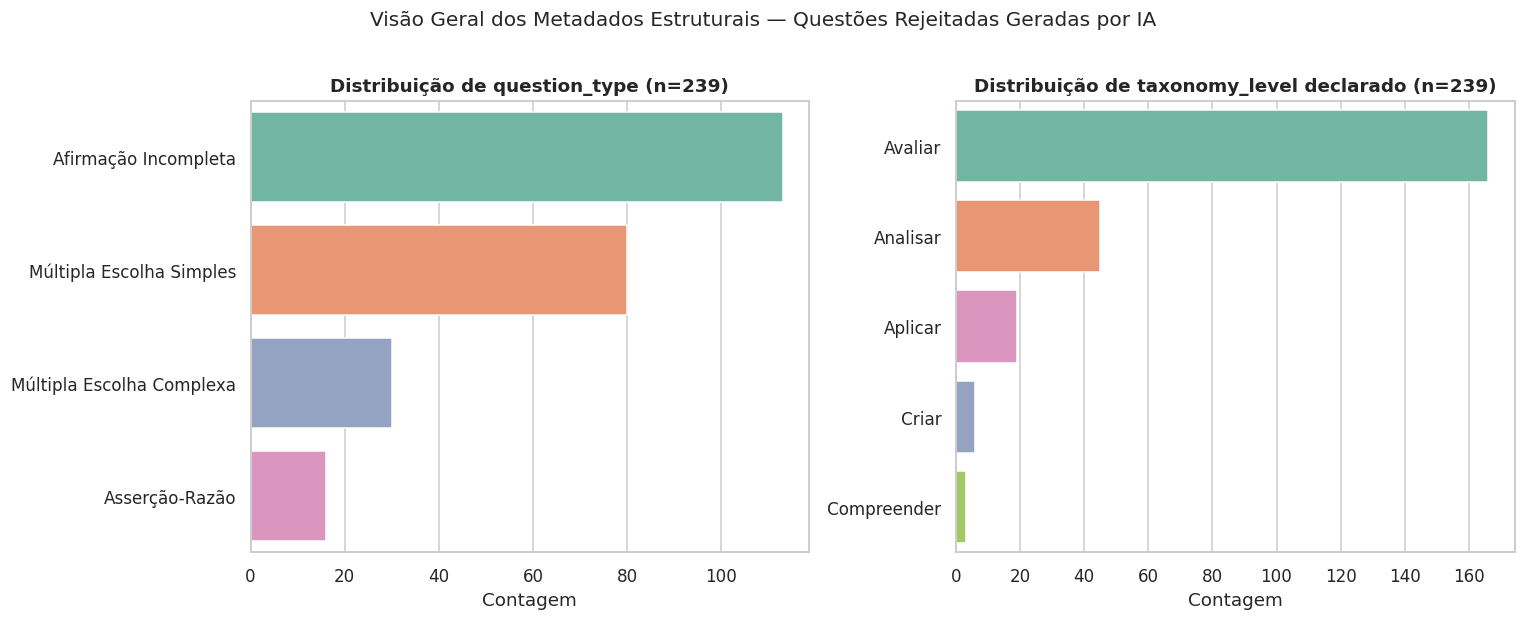

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

order_qt = df["question_type"].value_counts().index
sns.countplot(
    data=df, y="question_type", order=order_qt,
    hue="question_type", palette=QUALITATIVE_PALETTE, legend=False, ax=axes[0],
)
axes[0].set_title("Distribuição de question_type (n=239)")
axes[0].set_xlabel("Contagem")
axes[0].set_ylabel("")

order_tax = df["taxonomy_level"].value_counts().index
sns.countplot(
    data=df, y="taxonomy_level", order=order_tax,
    hue="taxonomy_level", palette=QUALITATIVE_PALETTE, legend=False, ax=axes[1],
)
axes[1].set_title("Distribuição de taxonomy_level declarado (n=239)")
axes[1].set_xlabel("Contagem")
axes[1].set_ylabel("")

fig.suptitle("Visão Geral dos Metadados Estruturais — Questões Rejeitadas Geradas por IA", y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_overview_distributions.png", bbox_inches="tight")
plt.show()


## 2. Verbosity Bias — Is `correct_option` a Length Outlier?

Per **R22** and the answer-length cueing flaw named in **R16** (Haladyna,
Downing & Rodriguez, 2002), a generator that paraphrases the correct answer
from source text while inventing distractors from scratch tends to leave the
correct option **systematically longer** (or, less commonly, shorter) than
its distractors — a structural giveaway a test-taker can exploit without any
domain knowledge.

For every item we compare the length of `correct_option` against the mean
length of its (up to 4) distractor options.

In [8]:
OPTION_COLS = ["option_a", "option_b", "option_c", "option_d", "option_e"]
LETTER_TO_COL = {"A": "option_a", "B": "option_b", "C": "option_c",
                  "D": "option_d", "E": "option_e"}

def option_lengths(row, unit="words"):
    lengths = {}
    for col in OPTION_COLS:
        text = row[col]
        if pd.isna(text):
            continue
        text = str(text)
        lengths[col] = len(text.split()) if unit == "words" else len(text)
    return lengths

def verbosity_stats(row, unit="words"):
    lengths = option_lengths(row, unit=unit)
    correct_col = LETTER_TO_COL.get(str(row["correct_option"]).strip().upper())
    if correct_col is None or correct_col not in lengths:
        return pd.Series({"correct_len": np.nan, "distractor_mean_len": np.nan,
                           "len_diff": np.nan, "is_longest": np.nan,
                           "is_shortest": np.nan, "n_options": len(lengths)})
    correct_len = lengths[correct_col]
    distractor_lens = [v for k, v in lengths.items() if k != correct_col]
    distractor_mean = np.mean(distractor_lens) if distractor_lens else np.nan
    all_lens = list(lengths.values())
    return pd.Series({
        "correct_len": correct_len,
        "distractor_mean_len": distractor_mean,
        "len_diff": correct_len - distractor_mean,
        "is_longest": correct_len == max(all_lens),
        "is_shortest": correct_len == min(all_lens),
        "n_options": len(lengths),
    })

verb_word = df.apply(lambda r: verbosity_stats(r, unit="words"), axis=1)
verb_char = df.apply(lambda r: verbosity_stats(r, unit="chars"), axis=1).add_suffix("_char")

df = pd.concat([df, verb_word, verb_char], axis=1)

print(df[["n_options", "correct_len", "distractor_mean_len", "len_diff"]].describe())


       n_options  correct_len  distractor_mean_len    len_diff
count      239.0   239.000000           239.000000  239.000000
mean         5.0    20.071130            17.784519    2.286611
std          0.0    13.374972            10.820422    4.555156
min          5.0     1.000000             1.000000   -9.750000
25%          5.0     9.500000             9.875000   -0.375000
50%          5.0    18.000000            16.250000    1.500000
75%          5.0    28.500000            25.750000    3.750000
max          5.0    79.000000            54.750000   37.500000


In [9]:
def bootstrap_ci(values, statistic=np.mean, n_boot=10_000, ci=95, rng=RNG):
    values = np.asarray(values)
    values = values[~np.isnan(values)]
    boot_stats = np.empty(n_boot)
    n = len(values)
    for i in range(n_boot):
        sample = values[rng.integers(0, n, size=n)]
        boot_stats[i] = statistic(sample)
    lower = np.percentile(boot_stats, (100 - ci) / 2)
    upper = np.percentile(boot_stats, 100 - (100 - ci) / 2)
    return statistic(values), lower, upper

mean_diff, ci_lo, ci_hi = bootstrap_ci(df["len_diff"].values)
wilcoxon_stat, wilcoxon_p = stats.wilcoxon(df["len_diff"].dropna())

pct_longest = df["is_longest"].mean() * 100
pct_shortest = df["is_shortest"].mean() * 100

print(f"Mean (correct_len - distractor_mean_len), in words: {mean_diff:+.2f}")
print(f"  95% bootstrap CI (n_boot=10,000, seed={SEED}): [{ci_lo:+.2f}, {ci_hi:+.2f}]")
print(f"Wilcoxon signed-rank test vs. 0: statistic={wilcoxon_stat:.1f}, p={wilcoxon_p:.4g}")
print(f"\ncorrect_option is the LONGEST of its options in  {pct_longest:.1f}% of items "
      f"(chance level for 5 options = 20.0%)")
print(f"correct_option is the SHORTEST of its options in {pct_shortest:.1f}% of items "
      f"(chance level for 5 options = 20.0%)")

# Explicit variance comparison (word- and character-based) as requested:
# does the correct option come from a systematically different length
# distribution than distractors, not just a different mean?
var_table = pd.DataFrame({
    "variance_words": [df["correct_len"].var(), df["distractor_mean_len"].var()],
    "variance_chars": [df["correct_len_char"].var(), df["distractor_mean_len_char"].var()],
}, index=["correct_option", "distractor_mean"])
print("\nOption-length variance (correct vs. distractor mean), words & characters:")
print(var_table.round(2))
levene_stat, levene_p = stats.levene(
    df["correct_len"].dropna(), df["distractor_mean_len"].dropna()
)
print(f"\nLevene's test for equal variances (correct vs. distractor mean length): "
      f"stat={levene_stat:.2f}, p={levene_p:.4g}")


Mean (correct_len - distractor_mean_len), in words: +2.29
  95% bootstrap CI (n_boot=10,000, seed=42): [+1.74, +2.88]
Wilcoxon signed-rank test vs. 0: statistic=4571.5, p=3.637e-16

correct_option is the LONGEST of its options in  49.8% of items (chance level for 5 options = 20.0%)
correct_option is the SHORTEST of its options in 26.4% of items (chance level for 5 options = 20.0%)

Option-length variance (correct vs. distractor mean), words & characters:
                 variance_words  variance_chars
correct_option           178.89         8497.01
distractor_mean          117.08         5531.49

Levene's test for equal variances (correct vs. distractor mean length): stat=7.02, p=0.00834


/tmp/ipykernel_16/1854806159.py:7: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.boxplot(


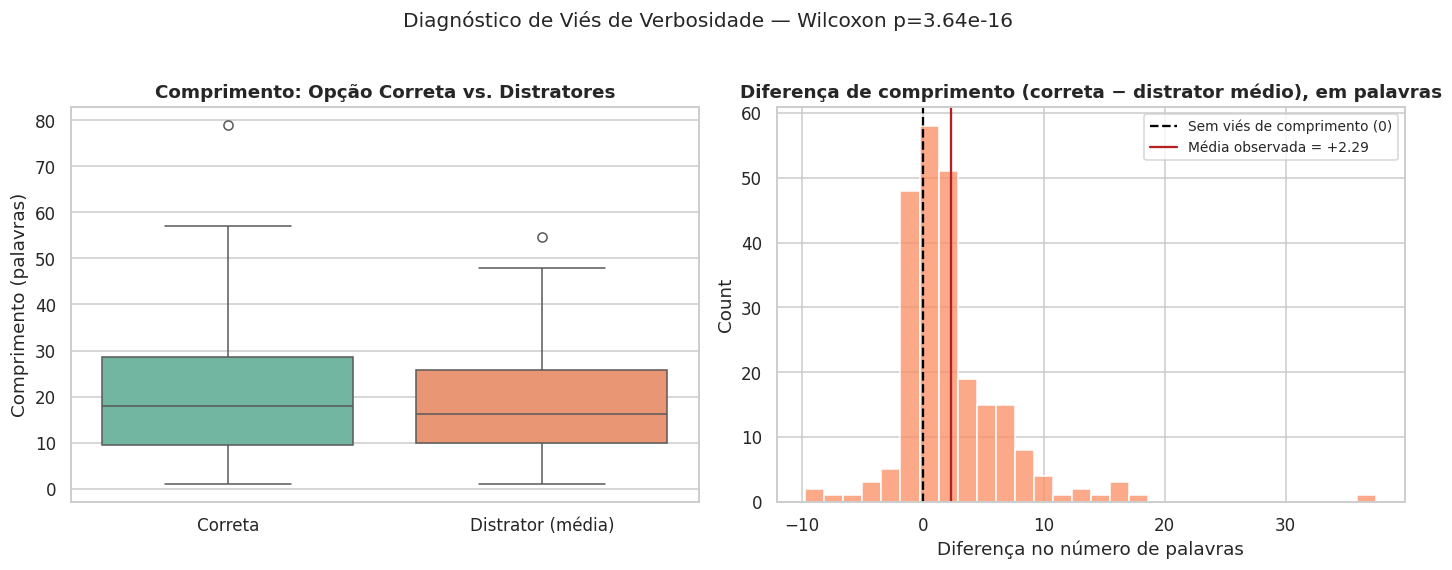

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_df = pd.DataFrame({
    "Papel da opção": ["Correta"] * len(df) + ["Distrator (média)"] * len(df),
    "Comprimento (palavras)": pd.concat([df["correct_len"], df["distractor_mean_len"]]).values,
})
sns.boxplot(
    data=plot_df, x="Papel da opção", y="Comprimento (palavras)",
    hue="Papel da opção", palette=QUALITATIVE_PALETTE, legend=False, ax=axes[0],
)
axes[0].set_title("Comprimento: Opção Correta vs. Distratores")
axes[0].set_xlabel("")

sns.histplot(df["len_diff"].dropna(), bins=30, color=QUALITATIVE_PALETTE[1], ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", linewidth=1.5, label="Sem viés de comprimento (0)")
axes[1].axvline(mean_diff, color="firebrick", linestyle="-", linewidth=1.5,
                 label=f"Média observada = {mean_diff:+.2f}")
axes[1].set_title("Diferença de comprimento (correta − distrator médio), em palavras")
axes[1].set_xlabel("Diferença no número de palavras")
axes[1].legend(loc="upper right", fontsize=9)

fig.suptitle(
    f"Diagnóstico de Viés de Verbosidade — Wilcoxon p={wilcoxon_p:.3g}", y=1.03
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_verbosity_bias.png", bbox_inches="tight")
plt.show()


/tmp/ipykernel_16/1767305667.py:3: UserWarning: The palette list has more values (8) than needed (4), which may not be intended.
  sns.boxplot(


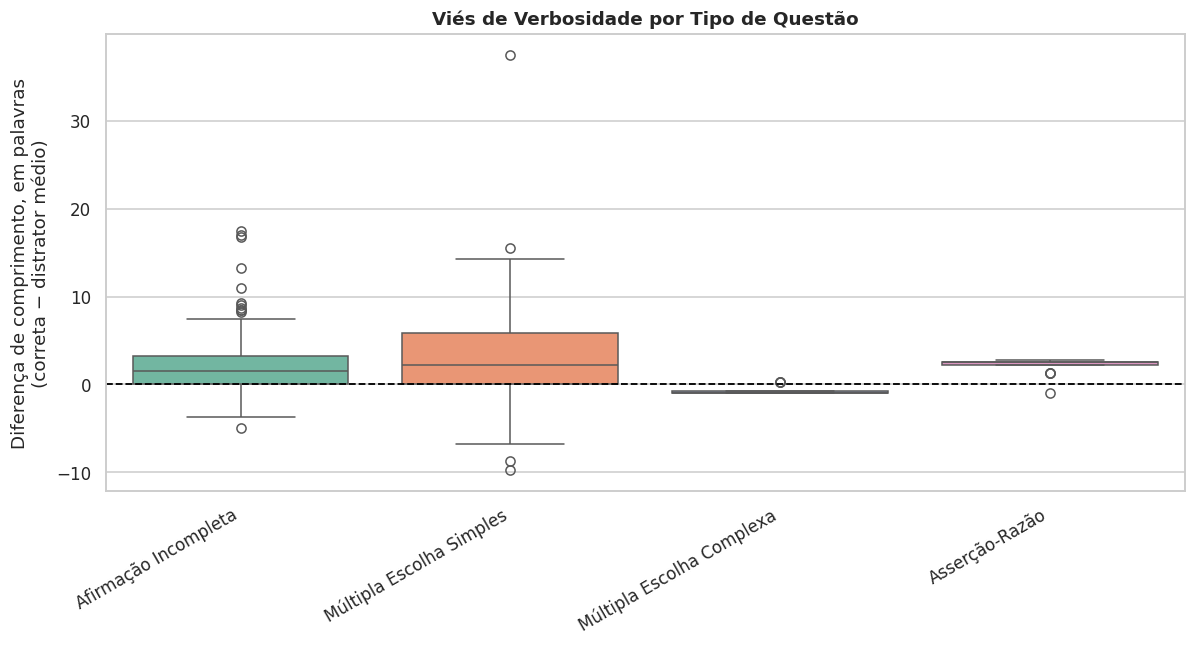

In [11]:
fig, ax = plt.subplots(figsize=(11, 6))
order_qt = df["question_type"].value_counts().index
sns.boxplot(
    data=df, x="question_type", y="len_diff", order=order_qt,
    hue="question_type", palette=QUALITATIVE_PALETTE, legend=False, ax=ax,
)
ax.axhline(0, color="black", linestyle="--", linewidth=1.2)
ax.set_title("Viés de Verbosidade por Tipo de Questão")
ax.set_xlabel("")
ax.set_ylabel("Diferença de comprimento, em palavras\n(correta − distrator médio)")
ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02b_verbosity_bias_by_question_type.png", bbox_inches="tight")
plt.show()


## 3. Position Bias — Distribution of `correct_option`

Per **R21** and the independence/non-cueing rule in **R16** (Downing,
*Handbook of Test Development*, ch. 12, Rule 22 — *"keep choices
independent"*), a well-formed item bank should place the correct answer
roughly uniformly across positions A–E (~20% each). A generator that
defaults to a fixed slot leaks a trivial, content-free heuristic to any
test-taker ("always guess A").

In [12]:
pos_counts = df["correct_option"].value_counts().reindex(list("ABCDE")).fillna(0).astype(int)
pos_props = pos_counts / pos_counts.sum()

print("correct_option distribution:")
print(pd.DataFrame({"count": pos_counts, "proportion": pos_props.round(4)}))

chi2, chi2_p = stats.chisquare(pos_counts.values)
print(f"\nChi-square goodness-of-fit vs. uniform (expected {pos_counts.sum()/5:.1f} each): "
      f"chi2={chi2:.2f}, p={chi2_p:.4g}")

p_a, p_a_lo, p_a_hi = bootstrap_ci((df["correct_option"] == "A").astype(float).values)
print(f"\nP(correct_option == 'A') = {p_a:.3f}  "
      f"95% bootstrap CI [{p_a_lo:.3f}, {p_a_hi:.3f}]  (chance level = 0.200)")


correct_option distribution:
                count  proportion
correct_option                   
A                 193      0.8075
B                  16      0.0669
C                  24      0.1004
D                   4      0.0167
E                   2      0.0084

Chi-square goodness-of-fit vs. uniform (expected 47.8 each): chi2=558.09, p=1.816e-119

P(correct_option == 'A') = 0.808  95% bootstrap CI [0.757, 0.858]  (chance level = 0.200)


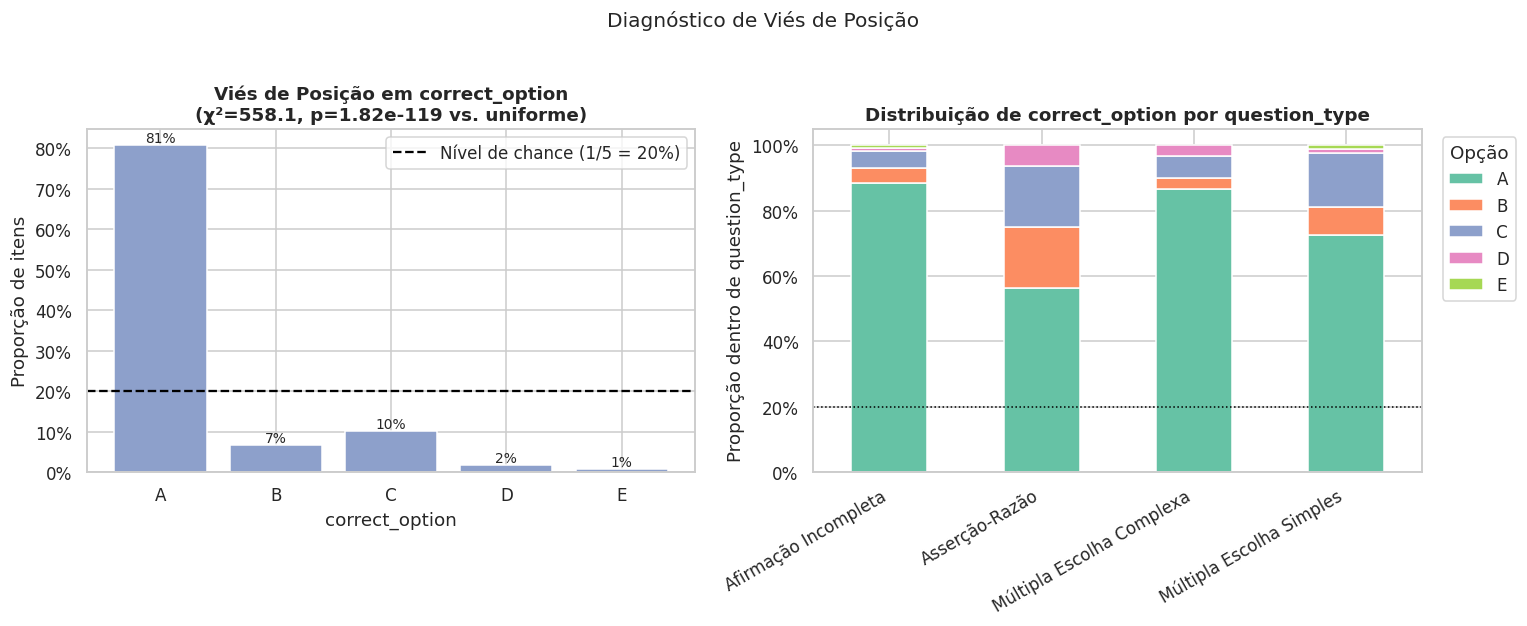

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

bars = axes[0].bar(pos_props.index, pos_props.values, color=QUALITATIVE_PALETTE[2])
axes[0].axhline(0.20, color="black", linestyle="--", linewidth=1.5,
                 label="Nível de chance (1/5 = 20%)")
axes[0].set_title(f"Viés de Posição em correct_option\n"
                    f"(χ²={chi2:.1f}, p={chi2_p:.2e} vs. uniforme)")
axes[0].set_ylabel("Proporção de itens")
axes[0].set_xlabel("correct_option")
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
axes[0].legend()
for bar, prop in zip(bars, pos_props.values):
    axes[0].annotate(f"{prop:.0%}", (bar.get_x() + bar.get_width() / 2, prop),
                       ha="center", va="bottom", fontsize=9)

ct = pd.crosstab(df["question_type"], df["correct_option"], normalize="index")
ct = ct.reindex(columns=list("ABCDE"), fill_value=0)
ct.plot(kind="bar", stacked=True, ax=axes[1], color=sns.color_palette("Set2", 5))
axes[1].axhline(0.20, color="black", linestyle=":", linewidth=1)
axes[1].set_title("Distribuição de correct_option por question_type")
axes[1].set_ylabel("Proporção dentro de question_type")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)
plt.setp(axes[1].get_xticklabels(), ha="right")
axes[1].legend(title="Opção", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))

fig.suptitle("Diagnóstico de Viés de Posição", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_position_bias.png", bbox_inches="tight")
plt.show()


## 4. Bloom's Taxonomy Verb-Level Mismatch

Per **R10**, a valid item must be generated/verified against a **fixed,
level-specific verb template** (e.g. *Avaliar* → criticar/julgar/avaliar;
*Analisar* → organizar/contrastar/comparar), never a free-form instruction.
We extract the governing verb(s) actually present in each item's `stem` and
cross-reference them against the **declared** `taxonomy_level`.

Two complementary extraction paths are implemented:
1. **Primary (spaCy, `pt_core_news_sm`)** — POS-tags and lemmatizes the stem,
   so conjugated verb forms ("avalie", "avaliando") are correctly normalized
   to their infinitive lemma before dictionary lookup.
2. **Fallback (pure regex, no dependency beyond the standard library)** —
   used automatically if the spaCy Portuguese model cannot be loaded (e.g. no
   network access at grading time). Matches word-initial roots of each
   Bloom-level verb, skipping tokens preceded by an article/preposition to
   reduce noun-vs-verb false positives (e.g. skip "a **análise**" but keep a
   bare "**avaliar**").

Both paths use the **same** Bloom verb bank below, built by translating
`constitution.md` R10's verb-bank table into Portuguese (matching this
dataset's `taxonomy_level` labels) and keeping each verb in exactly **one**
level, mirroring the mutual-exclusivity principle already required of rubric
criteria under R12.

In [14]:
BLOOM_VERBS_PT = {
    "Lembrar": ["definir", "identificar", "listar", "nomear", "reconhecer",
                "recordar", "memorizar", "citar", "enumerar"],
    "Compreender": ["resumir", "explicar", "interpretar", "exemplificar",
                     "parafrasear", "descrever", "traduzir"],
    "Aplicar": ["aplicar", "resolver", "implementar", "demonstrar",
                 "utilizar", "executar", "empregar", "calcular"],
    "Analisar": ["analisar", "organizar", "contrastar", "comparar",
                  "diferenciar", "examinar", "categorizar", "discriminar",
                  "investigar", "distinguir", "classificar"],
    "Avaliar": ["avaliar", "criticar", "julgar", "argumentar", "justificar",
                 "defender", "validar", "ponderar"],
    "Criar": ["criar", "projetar", "compor", "elaborar", "formular",
               "desenvolver", "propor", "planejar", "inventar", "produzir"],
}

# MCQ-legal levels per constitution R9 (Evaluate/Create must NOT be MCQ).
R9_MCQ_LEGAL_LEVELS = {"Lembrar", "Compreender", "Aplicar", "Analisar"}
R9_MCQ_ILLEGAL_LEVELS = {"Avaliar", "Criar"}

VERB_TO_LEVEL = {v: level for level, verbs in BLOOM_VERBS_PT.items() for v in verbs}
VERB_ROOTS = {v: v[:-2] if len(v) > 5 else v for v in VERB_TO_LEVEL}

def strip_accents(text):
    return "".join(
        c for c in unicodedata.normalize("NFD", text)
        if unicodedata.category(c) != "Mn"
    )


In [15]:
# --- Primary path: try spaCy pt_core_news_sm (auto-download if missing) ---
USE_SPACY = False
nlp = None
try:
    import spacy
    try:
        nlp = spacy.load("pt_core_news_sm")
    except OSError:
        print("pt_core_news_sm not found locally; attempting download "
              "(requires network)...")
        from spacy.cli import download as spacy_download
        spacy_download("pt_core_news_sm")
        nlp = spacy.load("pt_core_news_sm")
    USE_SPACY = True
    print("Verb extraction path: spaCy (pt_core_news_sm) lemmatization.")
except Exception as exc:  # pragma: no cover - environment dependent
    print(f"spaCy path unavailable ({exc!r}); falling back to regex-based "
          f"verb-root matching.")
    USE_SPACY = False


def extract_bloom_levels_spacy(text):
    doc = nlp(str(text))
    levels = set()
    for tok in doc:
        if tok.pos_ in ("VERB", "AUX"):
            lemma = tok.lemma_.lower()
            if lemma in VERB_TO_LEVEL:
                levels.add(VERB_TO_LEVEL[lemma])
    return levels


_ARTICLE_PREP = {"a", "o", "as", "os", "de", "da", "do", "das", "dos",
                  "em", "na", "no", "nas", "nos", "um", "uma"}

def extract_bloom_levels_regex(text):
    tokens = re.findall(r"[a-zà-ÿ]+", strip_accents(str(text)).lower())
    # (strip_accents already removes diacritics; regex kept broad for safety)
    levels = set()
    for i, tok in enumerate(tokens):
        prev = tokens[i - 1] if i > 0 else ""
        if prev in _ARTICLE_PREP:
            continue
        for verb, root in VERB_ROOTS.items():
            root_noacc = strip_accents(root)
            if tok.startswith(root_noacc) and len(tok) <= len(root_noacc) + 4:
                levels.add(VERB_TO_LEVEL[verb])
                break
    return levels


def extract_bloom_levels(text):
    if USE_SPACY:
        return extract_bloom_levels_spacy(text)
    return extract_bloom_levels_regex(text)


pt_core_news_sm not found locally; attempting download (requires network)...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 64.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Verb extraction path: spaCy (pt_core_news_sm) lemmatization.


In [16]:
detected_levels = df["stem"].apply(extract_bloom_levels)

def summarize_levels(levels):
    if len(levels) == 0:
        return "no_bloom_verb_detected"
    if len(levels) == 1:
        return next(iter(levels))
    return "ambiguous (" + "+".join(sorted(levels)) + ")"

df["inferred_taxonomy_level"] = detected_levels.apply(summarize_levels)
df["bloom_levels_detected_set"] = detected_levels

n_none = (df["inferred_taxonomy_level"] == "no_bloom_verb_detected").sum()
n_ambiguous = df["inferred_taxonomy_level"].str.startswith("ambiguous").sum()
n_single = len(df) - n_none - n_ambiguous

print(f"Stems with a single, unambiguous Bloom-level verb detected: {n_single} "
      f"({n_single/len(df):.1%})")
print(f"Stems with NO canonical Bloom verb detected:                {n_none} "
      f"({n_none/len(df):.1%})  -> violates R10's fixed-template requirement")
print(f"Stems with verbs spanning MULTIPLE Bloom levels:            {n_ambiguous} "
      f"({n_ambiguous/len(df):.1%})")

single_mask = ~df["inferred_taxonomy_level"].isin(["no_bloom_verb_detected"]) & \
              ~df["inferred_taxonomy_level"].str.startswith("ambiguous")
match_rate = (df.loc[single_mask, "inferred_taxonomy_level"]
                == df.loc[single_mask, "taxonomy_level"]).mean()
print(f"\nAmong items with an unambiguous verb match: declared == inferred in "
      f"{match_rate:.1%} of cases (mismatch rate = {1 - match_rate:.1%}).")


Stems with a single, unambiguous Bloom-level verb detected: 65 (27.2%)
Stems with NO canonical Bloom verb detected:                139 (58.2%)  -> violates R10's fixed-template requirement
Stems with verbs spanning MULTIPLE Bloom levels:            35 (14.6%)

Among items with an unambiguous verb match: declared == inferred in 30.8% of cases (mismatch rate = 69.2%).


**Important disaggregation (R34, R32).** The "no verb detected" figure
above should not be reported as one pooled number: `Afirmação Incompleta`
(incomplete-statement) items are, *by format*, declarative fill-in-the-blank
sentences — they structurally cannot carry an imperative Bloom command verb,
regardless of generation quality. Pooling them with genuinely verb-less
`Múltipla Escolha`/`Asserção-Razão` stems would conflate two different
failure modes (an unavoidable format property vs. an actual generation
defect), which is exactly the kind of single-pooled-statistic overclaim R34
exists to prevent. We split the rate by `question_type` below.

In [17]:
no_verb_by_type = (
    df.assign(no_verb=df["inferred_taxonomy_level"] == "no_bloom_verb_detected")
    .groupby("question_type")["no_verb"]
    .agg(["sum", "count", "mean"])
    .rename(columns={"sum": "n_no_verb", "count": "n_items", "mean": "rate"})
    .sort_values("rate", ascending=False)
)
print("Rate of 'no canonical Bloom verb detected' BY question_type:")
print(no_verb_by_type.assign(rate=no_verb_by_type["rate"].map("{:.1%}".format)))
print(
    "\nInterpretation: a high rate concentrated in 'Afirmacao Incompleta' reflects "
    "the declarative/fill-in-the-blank FORMAT itself (no verb slot exists), not "
    "necessarily a generation defect. A high rate in the MCQ/Assercao-Razao "
    "formats -- which DO have room for an imperative stem -- is the more direct "
    "R10 violation signal."
)


Rate of 'no canonical Bloom verb detected' BY question_type:
                           n_no_verb  n_items    rate
question_type                                        
Asserção-Razão                    16       16  100.0%
Múltipla Escolha Complexa         30       30  100.0%
Afirmação Incompleta              63      113   55.8%
Múltipla Escolha Simples          30       80   37.5%

Interpretation: a high rate concentrated in 'Afirmacao Incompleta' reflects the declarative/fill-in-the-blank FORMAT itself (no verb slot exists), not necessarily a generation defect. A high rate in the MCQ/Assercao-Razao formats -- which DO have room for an imperative stem -- is the more direct R10 violation signal.


### 4.1 Extending to the Full Cognitive Text

Spot-checking the `Asserção-Razão` and `Múltipla Escolha Complexa` stems that
scored "no verb detected" reveals **why** the rate is exactly 100% for both:
these two formats use a fully generic, templated `stem` —
*"A respeito dessas asserções, assinale a alternativa correta."* and
*"Considerando o contexto apresentado, é correto APENAS o que se afirma
em:"* — that structurally carries no content verb at all. The actual
cognitive-process verb for these formats lives in `assertion_i`/
`assertion_ii` (Asserção-Razão) or `statement_i`–`statement_iv` (Múltipla
Escolha Complexa), not in `stem`.

Reporting "no verb detected" from `stem` alone for these formats would be a
**false-confidence artifact** (R32) of the extraction method, not a
generation defect. We therefore build a `cognitive_text` field per item
(stem + whichever of assertion/statement fields are populated) and re-run
the same extraction on it — this becomes the primary, final metric used for
the confusion matrix and composite score below.

In [18]:
ASSERTION_COLS = ["assertion_i", "assertion_ii"]
STATEMENT_COLS = ["statement_i", "statement_ii", "statement_iii", "statement_iv"]

def build_cognitive_text(row):
    parts = [str(row["stem"])]
    for col in ASSERTION_COLS + STATEMENT_COLS:
        val = row[col]
        if pd.notna(val):
            parts.append(str(val))
    return " ".join(parts)

df["cognitive_text"] = df.apply(build_cognitive_text, axis=1)

detected_levels_full = df["cognitive_text"].apply(extract_bloom_levels)
df["inferred_taxonomy_level_full"] = detected_levels_full.apply(summarize_levels)

n_none_full = (df["inferred_taxonomy_level_full"] == "no_bloom_verb_detected").sum()
n_ambiguous_full = df["inferred_taxonomy_level_full"].str.startswith("ambiguous").sum()
n_single_full = len(df) - n_none_full - n_ambiguous_full

print(f"[stem-only]   no verb detected: {n_none} ({n_none/len(df):.1%})")
print(f"[full-text]   no verb detected: {n_none_full} ({n_none_full/len(df):.1%})")

no_verb_full_by_type = (
    df.assign(no_verb=df["inferred_taxonomy_level_full"] == "no_bloom_verb_detected")
    .groupby("question_type")["no_verb"]
    .mean()
    .sort_values(ascending=False)
)
print("\nRate of 'no verb detected' BY question_type, using full cognitive text:")
print(no_verb_full_by_type.map("{:.1%}".format))

single_mask_full = ~df["inferred_taxonomy_level_full"].isin(["no_bloom_verb_detected"]) & \
                    ~df["inferred_taxonomy_level_full"].str.startswith("ambiguous")
match_rate_full = (df.loc[single_mask_full, "inferred_taxonomy_level_full"]
                     == df.loc[single_mask_full, "taxonomy_level"]).mean()
print(f"\n[full-text] Among items with an unambiguous verb match: declared == inferred "
      f"in {match_rate_full:.1%} of cases (mismatch rate = {1 - match_rate_full:.1%}).")
print("This full-text metric is used as the primary Bloom-mismatch signal from "
      "here on (confusion matrix, composite flaw score, and Section 6 summary).")


[stem-only]   no verb detected: 139 (58.2%)
[full-text]   no verb detected: 96 (40.2%)

Rate of 'no verb detected' BY question_type, using full cognitive text:
question_type
Afirmação Incompleta         55.8%
Múltipla Escolha Simples     37.5%
Múltipla Escolha Complexa     6.7%
Asserção-Razão                6.2%
Name: no_verb, dtype: object

[full-text] Among items with an unambiguous verb match: declared == inferred in 31.8% of cases (mismatch rate = 68.2%).
This full-text metric is used as the primary Bloom-mismatch signal from here on (confusion matrix, composite flaw score, and Section 6 summary).


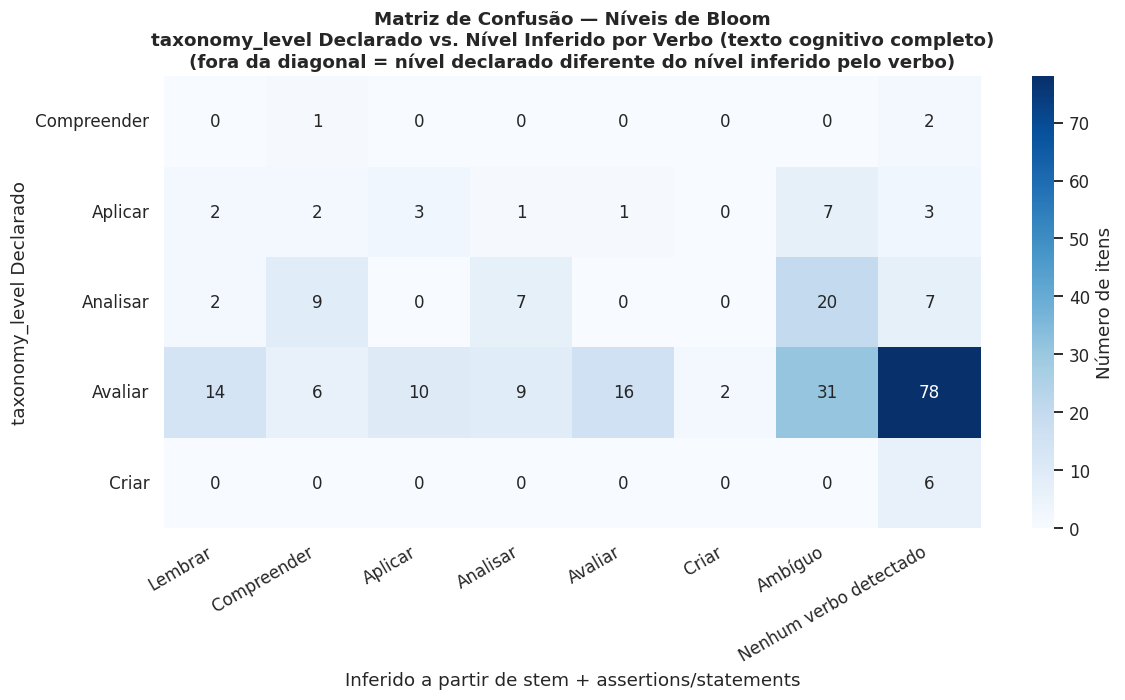

In [19]:
LEVEL_ORDER = ["Lembrar", "Compreender", "Aplicar", "Analisar", "Avaliar", "Criar"]
INFERRED_ORDER = LEVEL_ORDER + ["Ambíguo", "Nenhum verbo detectado"]

def collapse_inferred(x):
    if x.startswith("ambiguous"):
        return "Ambíguo"
    if x == "no_bloom_verb_detected":
        return "Nenhum verbo detectado"
    return x

df["inferred_taxonomy_level_full_display"] = df["inferred_taxonomy_level_full"].apply(collapse_inferred)

confusion = pd.crosstab(
    df["taxonomy_level"], df["inferred_taxonomy_level_full_display"]
)
confusion = confusion.reindex(index=[l for l in LEVEL_ORDER if l in confusion.index],
                                columns=[l for l in INFERRED_ORDER if l in confusion.columns],
                                fill_value=0)

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(confusion, annot=True, fmt="d", cmap=SEQUENTIAL_CMAP, cbar_kws={"label": "Número de itens"}, ax=ax)
ax.set_title("Matriz de Confusão — Níveis de Bloom\n"
              "taxonomy_level Declarado vs. Nível Inferido por Verbo (texto cognitivo completo)\n"
              "(fora da diagonal = nível declarado diferente do nível inferido pelo verbo)")
ax.set_xlabel("Inferido a partir de stem + assertions/statements")
ax.set_ylabel("taxonomy_level Declarado")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_bloom_confusion_matrix.png", bbox_inches="tight")
plt.show()


Items declared at Evaluate/Create level ('Avaliar'/'Criar') delivered as single-best-answer MCQ: 172 / 239 (72.0%)
These are, by R9, structurally invalid regardless of any other quality issue — the format itself is illegal for the declared cognitive level.


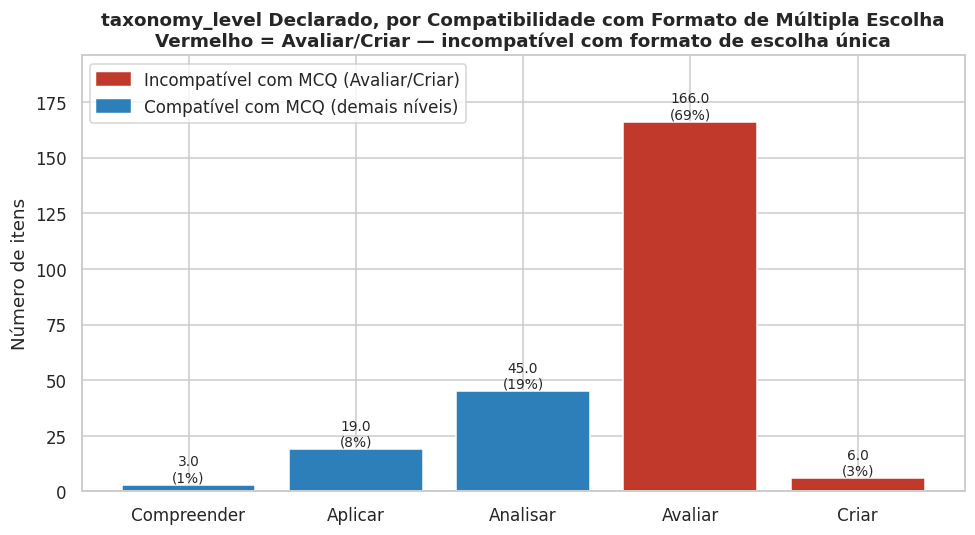

In [20]:
# --- R9: MCQ format is illegal for Evaluate/Create-level content ---
df["violates_r9"] = df["taxonomy_level"].isin(R9_MCQ_ILLEGAL_LEVELS)
n_r9 = df["violates_r9"].sum()
print(f"Items declared at Evaluate/Create level ('Avaliar'/'Criar') delivered as "
      f"single-best-answer MCQ: {n_r9} / {len(df)} ({n_r9/len(df):.1%})")
print("These are, by R9, structurally invalid regardless of any other quality issue "
      "— the format itself is illegal for the declared cognitive level.")

fig, ax = plt.subplots(figsize=(9, 5))
level_counts = df["taxonomy_level"].value_counts().reindex(LEVEL_ORDER).dropna()
colors = [
    "#c0392b" if lvl in R9_MCQ_ILLEGAL_LEVELS else "#2c7fb8"
    for lvl in level_counts.index
]
bars = ax.bar(level_counts.index, level_counts.values, color=colors)
ax.set_title(
    "taxonomy_level Declarado, por Compatibilidade com Formato de Múltipla Escolha\n"
    "Vermelho = Avaliar/Criar — incompatível com formato de escolha única"
)
ax.set_ylabel("Número de itens")
ax.set_ylim(0, level_counts.values.max() * 1.18)
for bar, val in zip(bars, level_counts.values):
    ax.annotate(f"{val}\n({val/len(df):.0%})", (bar.get_x() + bar.get_width()/2, val),
                 ha="center", va="bottom", fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#c0392b", label="Incompatível com MCQ (Avaliar/Criar)"),
                     Patch(color="#2c7fb8", label="Compatível com MCQ (demais níveis)")],
          loc="upper left")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_r9_format_violation.png", bbox_inches="tight")
plt.show()


## 5. Composite Structural Flaw Score (Bonus, No Model Involved)

A simple, transparent rule-count (not a learned score) tallying how many of
the diagnosed structural flaws co-occur in the same item. This is descriptive
bookkeeping over the flags already computed above — useful for prioritizing
which items in the Technical Report to show as illustrative examples.

In [21]:
df["flag_position_bias"] = df["correct_option"] == "A"
df["flag_verbosity_outlier"] = df["is_longest"].fillna(False)
# Uses the full-cognitive-text inference (Section 4.1), not the stem-only one,
# since stem-only conflates "no verb slot in this format" with "generation
# defect" for Assercao-Razao / Multipla Escolha Complexa (see R32 note above).
df["flag_bloom_mismatch"] = single_mask_full & (
    df["inferred_taxonomy_level_full"] != df["taxonomy_level"]
)
df["flag_r9_violation"] = df["violates_r9"]

FLAG_COLS = ["flag_position_bias", "flag_verbosity_outlier",
             "flag_bloom_mismatch", "flag_r9_violation"]
df["structural_flaw_count"] = df[FLAG_COLS].sum(axis=1)

print(df[FLAG_COLS + ["structural_flaw_count"]].sum())
print(f"\nMean flaws per item: {df['structural_flaw_count'].mean():.2f} "
      f"(out of {len(FLAG_COLS)} tracked)")
print(f"Items with ZERO tracked flaws: {(df['structural_flaw_count'] == 0).sum()} "
      f"({(df['structural_flaw_count'] == 0).mean():.1%}) — rejected for reasons "
      f"outside this notebook's four structural checks (e.g. factual error, "
      f"human-only-detectable ambiguity).")


flag_position_bias        193
flag_verbosity_outlier    119
flag_bloom_mismatch        58
flag_r9_violation         172
structural_flaw_count     542
dtype: int64

Mean flaws per item: 2.27 (out of 4 tracked)
Items with ZERO tracked flaws: 4 (1.7%) — rejected for reasons outside this notebook's four structural checks (e.g. factual error, human-only-detectable ambiguity).


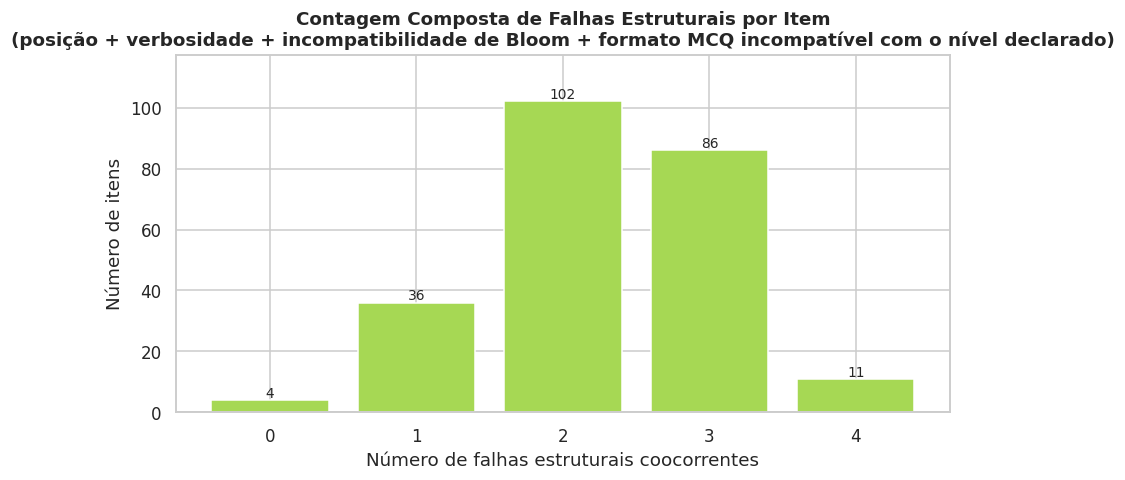

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
counts = df["structural_flaw_count"].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color=QUALITATIVE_PALETTE[4])
ax.set_title("Contagem Composta de Falhas Estruturais por Item\n"
              "(posição + verbosidade + incompatibilidade de Bloom + formato MCQ incompatível com o nível declarado)")
ax.set_xlabel("Número de falhas estruturais coocorrentes")
ax.set_ylabel("Número de itens")
ax.set_ylim(0, counts.values.max() * 1.15)
for i, v in zip(counts.index.astype(str), counts.values):
    ax.annotate(str(v), (i, v), ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_composite_flaw_count.png", bbox_inches="tight")
plt.show()


In [23]:
summary_cols = [
    "question_id", "discipline", "question_type", "taxonomy_level",
    "inferred_taxonomy_level", "inferred_taxonomy_level_full",
    "correct_option", "correct_len", "distractor_mean_len", "len_diff",
] + FLAG_COLS + ["structural_flaw_count"]

flaw_summary = df[summary_cols].sort_values("structural_flaw_count", ascending=False)
flaw_summary.to_csv(OUTPUT_DIR / "flaw_summary.csv", index=False, encoding="utf-8")
print(f"Saved per-item flaw summary to {OUTPUT_DIR / 'flaw_summary.csv'} "
      f"({len(flaw_summary)} rows).")
flaw_summary.head(10)


Saved per-item flaw summary to output/flaw_summary.csv (239 rows).


,question_id,discipline,question_type,taxonomy_level,inferred_taxonomy_level,inferred_taxonomy_level_full,correct_option,correct_len,distractor_mean_len,len_diff,flag_position_bias,flag_verbosity_outlier,flag_bloom_mismatch,flag_r9_violation,structural_flaw_count
19,63,FISIOTERAPIA DERMATOFUNCIONAL,Afirmação Incompleta,Avaliar,Compreender,Compreender,A,39,30.00,9.00,True,True,True,True,4
30,98,CONEXÃO SEM BARREIRAS EM SAÚDE,Afirmação Incompleta,Avaliar,Lembrar,Lembrar,A,36,33.00,3.00,True,True,True,True,4
71,251,Morfossintaxe da Língua Inglesa,Afirmação Incompleta,Avaliar,Analisar,Analisar,A,6,5.50,0.50,True,True,True,True,4
107,392,Geografia Econômica,Afirmação Incompleta,Avaliar,Lembrar,Lembrar,A,17,14.50,2.50,True,True,True,True,4
164,559,Educação de Jovens e Adultos,Afirmação Incompleta,Avaliar,Criar,Criar,A,21,19.00,2.00,True,True,True,True,4
154,528,Geografia Econômica,Afirmação Incompleta,Avaliar,Lembrar,Lembrar,A,12,4.75,7.25,True,True,True,True,4
132,457,Semântica,Afirmação Incompleta,Avaliar,Lembrar,Lembrar,A,17,13.25,3.75,True,True,True,True,4
179,623,Geografia Econômica,Afirmação Incompleta,Avaliar,Analisar,Analisar,A,14,11.50,2.50,True,True,True,True,4
221,779,Geografia Econômica,Afirmação Incompleta,Avaliar,Lembrar,Lembrar,A,16,13.75,2.25,True,True,True,True,4
215,766,ARTE CONTEMPORÂNEA,Múltipla Escolha Simples,Avaliar,Lembrar,Lembrar,A,54,46.50,7.50,True,True,True,True,4


## 6. Summary of Findings — for the WAPLA Technical Report

The cell below prints an auto-generated summary sourced directly from the
statistics computed above (no hardcoded numbers), so it stays accurate if the
notebook is re-run against a dataset revision.

In [24]:
summary = f'''
STRUCTURAL DIAGNOSIS SUMMARY - {len(df)} Rejected AI-Generated Questions
================================================================

1) VERBOSITY BIAS (R16, R22)
   - Mean (correct - mean distractor) length: {mean_diff:+.2f} words
     [95% bootstrap CI: {ci_lo:+.2f}, {ci_hi:+.2f}] (Wilcoxon p={wilcoxon_p:.3g})
   - correct_option is the LONGEST option in {pct_longest:.1f}% of items
     (chance level: 20.0%)

2) POSITION BIAS (R21, R16)
   - P(correct_option == "A") = {p_a:.1%} [95% CI: {p_a_lo:.1%}, {p_a_hi:.1%}]
     vs. chance level of 20.0%
   - Chi-square goodness-of-fit vs. uniform: chi2={chi2:.1f}, p={chi2_p:.3g}

3) BLOOM'S TAXONOMY MISMATCH (R6-R11)
   - Using full cognitive text (stem + assertions/statements, Section 4.1):
     {n_none_full} items ({n_none_full/len(df):.1%}) contain NO canonical
     Bloom-level verb anywhere in the item -- violates R10's fixed-template
     requirement
   - Among items with an unambiguous verb match, declared/inferred level
     mismatch rate: {1 - match_rate_full:.1%}
   - (Diagnostic note: stem-only extraction found {n_none} items ({n_none/len(df):.1%})
     with no verb, but 100% of that figure for Assercao-Razao/Multipla Escolha
     Complexa was a format artifact -- generic boilerplate stems -- not a
     generation defect; see Section 4.1)
   - {n_r9} items ({n_r9/len(df):.1%}) are declared Evaluate/Create-level
     content delivered in a single-best-answer MCQ format -- structurally
     illegal under R9 regardless of any other quality dimension

4) COMPOSITE
   - Mean tracked structural flaws per item: {df["structural_flaw_count"].mean():.2f} / 4
   - Items with zero tracked flaws (rejected for other reasons):
     {(df["structural_flaw_count"] == 0).sum()} ({(df["structural_flaw_count"] == 0).mean():.1%})

All figures saved to: {OUTPUT_DIR.resolve()}
'''
print(summary)

with open(OUTPUT_DIR / "eda_summary.txt", "w", encoding="utf-8") as f:
    f.write(summary)



STRUCTURAL DIAGNOSIS SUMMARY - 239 Rejected AI-Generated Questions

1) VERBOSITY BIAS (R16, R22)
   - Mean (correct - mean distractor) length: +2.29 words
     [95% bootstrap CI: +1.74, +2.88] (Wilcoxon p=3.64e-16)
   - correct_option is the LONGEST option in 49.8% of items
     (chance level: 20.0%)

2) POSITION BIAS (R21, R16)
   - P(correct_option == "A") = 80.8% [95% CI: 75.7%, 85.8%]
     vs. chance level of 20.0%
   - Chi-square goodness-of-fit vs. uniform: chi2=558.1, p=1.82e-119

3) BLOOM'S TAXONOMY MISMATCH (R6-R11)
   - Using full cognitive text (stem + assertions/statements, Section 4.1):
     96 items (40.2%) contain NO canonical
     Bloom-level verb anywhere in the item -- violates R10's fixed-template
     requirement
   - Among items with an unambiguous verb match, declared/inferred level
     mismatch rate: 68.2%
   - (Diagnostic note: stem-only extraction found 139 items (58.2%)
     with no verb, but 100% of that figure for Assercao-Razao/Multipla Escolha
     Compl

## End of Deliverable 1 (EDA)

The section above is **strictly EDA** — no model was trained or fine-tuned. The findings are structural evidence for the WAPLA Technical Report, and are consumed directly by **Deliverable 2**, which follows below in this same notebook:

- **spec.md §4.2.1** (Bias-Mitigated Judge Protocol) — implemented below as the Generator↔Judge pipeline's mechanical pre-filter + LLM Judge blind-solve.
- **spec.md §4.4** (IRT Calibration Layer) — not implemented (out of scope for this deliverable; see `CONTEXT.md` §4).
- **Rubric/verb templates (R10)** — the `BLOOM_VERBS_PT` bank defined above is reused verbatim by Deliverable 2 below (not redefined — see the AIG-1 section), closing the manual-sync risk noted in `CONTEXT.md` §6.

`flaw_summary.csv`, written above, is the **hard input contract** for everything that follows.

# Deliverable 2 — AIG Refinement Engine (Generator ↔ Judge Pipeline)

Ported from `WAPLA_AIG_Engine.py` into this notebook. Implements `spec.md` §4 (Multi-Agent Generator↔Judge Architecture) and §4.2.1 (Bias-Mitigated Judge Protocol), with **explicitly documented deliberate deviations** from the literal spec text:

- `spec.md` §4.2 step 1 describes a **trained** learning-dynamics classifier (Seedat's CLLM curator). This deliverable's brief forbids training any model, so that stage is reimplemented as a deterministic, rule-based **mechanical pre-filter** — architecturally the same role (a cheap, non-LLM gate that runs before the expensive LLM Judge call), just without a trained classifier behind it.
- `spec.md` §4.2.1 step 1 specifies majority-vote over ≥10 option reorderings for MCQ position-bias auditing of the judge. At 100 items × up to 4 attempts, that is hundreds of extra judge calls just for this check. The default here is a single-shuffle "blind-solve" decorrelation (still model-agnostic to which letter is being graded); the full 10-reordering majority vote is available via `RIGOROUS_POSITION_CHECK = True` for a smaller or higher-stakes batch.
- `spec.md` §4.2.1 step 5 (leniency check against a human SME baseline) cannot be performed inside a fully automated script — there is no human reviewer here. This is logged as an explicit, unresolved gap in the final run summary rather than silently skipped.

**Consolidation note.** `CONTEXT.md` §6 flagged that the standalone `.py` engine duplicated the Bloom verb bank and verb-extraction logic from the notebook "for narrative/methodological consistency", kept in sync by hand. Now that both deliverables live in one notebook, that duplication is eliminated: Section AIG-1 below reuses the exact `BLOOM_VERBS_PT`, `LEVEL_ORDER`, `R9_MCQ_*_LEVELS`, `VERB_TO_LEVEL`, `strip_accents`, and `extract_bloom_levels` objects already built in Deliverable 1's Section 4 above, rather than redefining them.

## AIG-0. Reproducibility, Paths, Logging & Kaggle Secrets

In [25]:
import asyncio
import json
import logging
from dataclasses import dataclass, field
from datetime import datetime, timezone
from typing import Literal, Optional

# SEED, RNG (numpy, used by bootstrap_ci above), and OUTPUT_DIR are already
# defined and seeded in the "0. Setup, Reproducibility & Output Directory"
# cell above (Deliverable 1) -- reused here unchanged so both deliverables
# share one reproducibility seed and one output folder. A SEPARATE, dedicated
# stdlib random.Random instance is created below for Deliverable 2's own
# shuffling needs (option-letter assignment, distractor ordering) -- named
# ENGINE_RNG (not RNG, which is already the Deliverable 1 numpy Generator) to
# avoid a name collision between the two deliverables' originally-separate
# "RNG" globals now that they share one namespace.
ENGINE_RNG = random.Random(SEED)

FLAW_SUMMARY_PATH = OUTPUT_DIR / "flaw_summary.csv"
DELIVERABLE_PATH = OUTPUT_DIR / "entregavel_2_100_questoes.csv"
AUDIT_TRAIL_PATH = OUTPUT_DIR / "aig_audit_trail.jsonl"
JUDGE_BIAS_AUDIT_PATH = OUTPUT_DIR / "judge_bias_audit_log.json"
LOG_PATH = OUTPUT_DIR / "aig_engine.log"

HF_DATASET_ID = "aiboxlab/ai-generated-questions-quality"  # same dataset loaded in Section 1 above

# Exact column order required by the competition (distinct from the source
# dataset's internal column order).
COMPETITION_SCHEMA = [
    "question_id", "question_type", "discipline", "taxonomy_level",
    "base_text", "stem", "assertion_i", "assertion_ii",
    "statement_i", "statement_ii", "statement_iii", "statement_iv",
    "option_a", "option_b", "option_c", "option_d", "option_e",
    "correct_option",
]

# OPTION_COLS and LETTER_TO_COL were already defined in Section 2 above
# (Verbosity Bias); OPTION_LETTERS is derived from that same mapping here
# rather than redefined, so both deliverables agree on option-letter order
# by construction.
OPTION_LETTERS = list(LETTER_TO_COL.keys())

# "standard" formats have free-text, LLM-authored options where mutual
# exclusivity is a real, checkable risk (R12/R13). "complex_mc" and
# "assertion_reason" options are orchestrator-templated (see
# place_options_at_letters below) and mutually exclusive BY CONSTRUCTION --
# their text legitimately shares heavy boilerplate, which would make a naive
# similarity check on them a systematic false-positive generator.
QUESTION_FORMAT = {
    "Múltipla Escolha Simples": "standard",
    "Afirmação Incompleta": "standard",
    "Múltipla Escolha Complexa": "complex_mc",
    "Asserção-Razão": "assertion_reason",
}

# --- Logging ---
logger = logging.getLogger("wapla_aig_engine")
logger.setLevel(logging.DEBUG)
logger.handlers.clear()

_console = logging.StreamHandler()
_console.setLevel(logging.INFO)
_console.setFormatter(logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%H:%M:%S"))
logger.addHandler(_console)


def _attach_file_logging() -> None:
    """Deliberately NOT called at cell-execution time below (only from the
    Run Configuration cell, when RUN_PIPELINE_NOW=True): a FileHandler opened
    in mode='w' would truncate output/aig_engine.log every time this cell
    re-runs, not only when the pipeline actually executes."""
    file_handler = logging.FileHandler(LOG_PATH, mode="w", encoding="utf-8")
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)-7s | %(name)s | %(message)s"))
    logger.addHandler(file_handler)


print(f"Deliverable 2 paths ready. Reusing OUTPUT_DIR={OUTPUT_DIR.resolve()}, SEED={SEED}.")

Deliverable 2 paths ready. Reusing OUTPUT_DIR=/kaggle/working/output, SEED=42.


### Kaggle Secrets → API keys

On Kaggle, attach each provider's API key via **Notebook → Add-ons → Secrets**, using the exact labels below (these are also the environment-variable names `litellm` expects). Locally (outside Kaggle), set the same names as OS environment variables instead. Only the provider(s) actually referenced by `GENERATOR_MODEL`/`JUDGE_MODEL` in the Run Configuration cell below need a secret attached — missing ones for unused providers are silently skipped.

In [26]:
import os

try:
    from kaggle_secrets import UserSecretsClient
    _user_secrets = UserSecretsClient()
    _ON_KAGGLE = True
except ImportError:
    _user_secrets = None
    _ON_KAGGLE = False

# Candidate secret/env-var names for every provider this engine's
# GENERATOR_MODEL / JUDGE_MODEL might point at (litellm's expected names).
_CANDIDATE_SECRET_NAMES = [
    "GROQ_API_KEY", "OPENAI_API_KEY", "GEMINI_API_KEY",
    "GOOGLE_API_KEY", "ANTHROPIC_API_KEY",
]

for _name in _CANDIDATE_SECRET_NAMES:
    if os.environ.get(_name):
        continue
    if _user_secrets is None:
        continue
    try:
        os.environ[_name] = _user_secrets.get_secret(_name)
        print(f"Loaded {_name} from Kaggle Secrets.")
    except Exception:
        pass  # secret not attached to this notebook -- fine if that provider isn't used

if not _ON_KAGGLE:
    print("kaggle_secrets not available (not running on Kaggle) -- relying on "
          "whatever API key environment variables are already set locally.")

## AIG-1. Bloom Verb Bank & Cognitive-Level Logic — Reused from Deliverable 1

Nothing is redefined here: `BLOOM_VERBS_PT`, `LEVEL_ORDER`, `R9_MCQ_LEGAL_LEVELS`/`R9_MCQ_ILLEGAL_LEVELS`, `VERB_TO_LEVEL`, `strip_accents`, and `extract_bloom_levels` are the exact objects Deliverable 1 built in its Section 4 above. Only the two functions genuinely specific to Deliverable 2 are added below.

In [27]:
def determine_target_level(original_level: str) -> tuple[str, bool]:
    """Constitution R9: MCQ format is illegal for Evaluate/Create-level
    content. Since the competition deliverable's schema mandates a
    single-best-answer MCQ output for every item, an item declared
    Avaliar/Criar is demoted to Analisar (the nearest legal MCQ ceiling)
    rather than shipped as a self-contradictory R9 violation. Returns
    (target_level, was_demoted)."""
    if original_level in R9_MCQ_ILLEGAL_LEVELS:
        return "Analisar", True
    if original_level not in LEVEL_ORDER:
        # Unrecognized/missing declared level: default to the most common
        # legal level in this dataset rather than guessing at random.
        return "Analisar", True
    return original_level, False


def build_cognitive_text_dict(item: dict) -> str:
    """Dict-based counterpart to Section 4.1's build_cognitive_text(row)
    above -- operates on a GeneratedItem.model_dump() dict instead of a
    pandas Row, since Deliverable 2 works with freshly-generated (not yet
    tabular) items."""
    parts = [str(item.get("stem", "") or "")]
    for col in ("assertion_i", "assertion_ii", "statement_i", "statement_ii",
                "statement_iii", "statement_iv"):
        val = item.get(col)
        if val:
            parts.append(str(val))
    return " ".join(parts)

## AIG-2. Data Loading & Candidate Pool

Mirrors `WAPLA_AIG_Engine.py` §5. `build_candidate_pool()` merges `flaw_summary.csv` (written by Deliverable 1 above) with a fresh copy of the original dataset, ranked by `structural_flaw_count` descending. It deliberately re-reads `flaw_summary.csv` from **disk** rather than reusing the in-memory `flaw_summary` DataFrame above — this preserves the same hard on-disk contract documented in `CONTEXT.md` §6, so this section still works unmodified if the kernel is restarted and only this section is re-run against an existing `output/flaw_summary.csv`.

In [28]:
def load_original_dataset() -> pd.DataFrame:
    from datasets import load_dataset as _load_dataset
    ds = _load_dataset(HF_DATASET_ID)
    split_name = "train" if "train" in ds else list(ds.keys())[0]
    if split_name != "train":
        logger.info("Dataset has no 'train' split; using '%s' instead.", split_name)
    return ds[split_name].to_pandas()


def build_candidate_pool(pool_size: Optional[int] = None) -> pd.DataFrame:
    """Merges flaw_summary.csv (from Deliverable 1 above) with the original
    dataset on question_id, ranks by structural_flaw_count descending (ties
    broken deterministically by question_id), and returns the ranked
    candidate pool the orchestrator will work through."""
    if not FLAW_SUMMARY_PATH.exists():
        raise FileNotFoundError(
            f"{FLAW_SUMMARY_PATH} not found. Run the Deliverable 1 (EDA) "
            f"cells above first -- this engine consumes their structural-flaw "
            f"diagnosis, it does not recompute it."
        )
    flaws = pd.read_csv(FLAW_SUMMARY_PATH)
    original = load_original_dataset()

    merged = original.merge(
        flaws[["question_id", "structural_flaw_count", "flag_position_bias",
               "flag_verbosity_outlier", "flag_bloom_mismatch", "flag_r9_violation",
               "inferred_taxonomy_level_full"]],
        on="question_id", how="inner", validate="one_to_one",
    )
    if len(merged) != len(original):
        logger.warning(
            "flaw_summary.csv covers %d/%d original items; %d could not be "
            "matched and are excluded from the candidate pool.",
            len(merged), len(original), len(original) - len(merged),
        )

    merged = merged.sort_values(
        ["structural_flaw_count", "question_id"], ascending=[False, True]
    ).reset_index(drop=True)

    if pool_size is not None:
        merged = merged.head(pool_size)
    logger.info("Candidate pool built: %d items (flaw_count range %d-%d).",
                len(merged), merged["structural_flaw_count"].max(), merged["structural_flaw_count"].min())
    return merged

## AIG-3. Programmatic Option Placement (Position-Bias Control, R21)

The correct answer's slot is assigned **programmatically** by the orchestrator, not left to the generator LLM's own (documented, unreliable) sense of randomness. `Asserção-Razão` and `Múltipla Escolha Complexa` options are further generated from fixed, orchestrator-owned templates rather than free LLM text, which structurally guarantees mutual exclusivity (R12/R13) and removes the verbosity-bias surface entirely (R22) for those two formats.

In [29]:
# Canonical, fixed Assercao-Razao answer template (constitution R12/R16:
# mutually-exclusive-by-construction, since each option encodes a distinct
# logical pattern). Kept as literal Python data, never LLM-authored.
ASSERTION_REASON_TEMPLATES: list[dict] = [
    {"pattern": "both_true_ii_justifies_i",
     "text": "As duas asserções são proposições verdadeiras, e a segunda é uma justificativa correta da primeira."},
    {"pattern": "both_true_ii_does_not_justify_i",
     "text": "As duas asserções são proposições verdadeiras, mas a segunda não é uma justificativa correta da primeira."},
    {"pattern": "i_true_ii_false",
     "text": "A primeira asserção é uma proposição verdadeira, e a segunda é uma proposição falsa."},
    {"pattern": "i_false_ii_true",
     "text": "A primeira asserção é uma proposição falsa, e a segunda é uma proposição verdadeira."},
    {"pattern": "both_false",
     "text": "As duas asserções são proposições falsas."},
]


def assign_target_letters(n: int) -> list[str]:
    """Constitution R21 (position bias): a balanced multiset of A-E,
    shuffled once with the global seed, guarantees a near-uniform
    correct_option distribution in the output by construction rather than
    by hope."""
    letters = (OPTION_LETTERS * ((n // len(OPTION_LETTERS)) + 1))[:n]
    ENGINE_RNG.shuffle(letters)
    return letters


def assign_assertion_reason_patterns(n: int) -> list[dict]:
    templates = (ASSERTION_REASON_TEMPLATES * ((n // len(ASSERTION_REASON_TEMPLATES)) + 1))[:n]
    ENGINE_RNG.shuffle(templates)
    return templates


def get_assertion_reason_distractors(true_pattern: dict) -> list[str]:
    return [t["text"] for t in ASSERTION_REASON_TEMPLATES if t["pattern"] != true_pattern["pattern"]]


def build_complex_mc_combination(rng: random.Random) -> dict:
    """Multipla Escolha Complexa: the option_a-e texts observed in this
    dataset are combinatorial phrases over the four roman-numeral statements
    ('I e III estão corretas', ...), not free-content distractors.
    Generating them programmatically -- rather than asking the LLM to author
    five paraphrase-style options -- structurally guarantees mutual
    exclusivity (R12/R13: each option names a distinct statement subset, so
    at most one can be true) and removes the verbosity-bias surface entirely
    (R22). Returns the true subset plus four distractor subsets/texts,
    UNPLACED -- the caller assigns letters via place_options_at_letters."""
    from itertools import combinations

    numerals = ["I", "II", "III", "IV"]
    all_subsets = [c for size in (2, 3, 4) for c in combinations(numerals, size)]
    true_subset = tuple(rng.sample(all_subsets, 1)[0])
    distractor_pool = [s for s in all_subsets if s != true_subset]
    distractor_subsets = rng.sample(distractor_pool, 4)

    def subset_to_text(subset: tuple) -> str:
        if len(subset) == 1:
            return f"{subset[0]} está correta"
        return f"{', '.join(subset[:-1])} e {subset[-1]} estão corretas"

    return {
        "true_subset": true_subset,
        "true_text": subset_to_text(true_subset),
        "distractor_texts": [subset_to_text(s) for s in distractor_subsets],
    }


def place_options_at_letters(target_letter: str, true_text: str,
                              distractor_texts: list[str], rng: random.Random) -> dict[str, str]:
    """Shared placement logic for both orchestrator-templated formats
    (Multipla Escolha Complexa, Assercao-Razao): the TRUE option goes at the
    corpus-wide-balanced target_letter (R21); the four distractors fill the
    remaining letters in a locally shuffled order."""
    remaining_letters = [l for l in OPTION_LETTERS if l != target_letter]
    shuffled_distractors = list(distractor_texts)
    rng.shuffle(shuffled_distractors)
    placement = {target_letter: true_text}
    placement.update(dict(zip(remaining_letters, shuffled_distractors)))
    return placement


def apply_position_shuffle(item: "GeneratedItem", target_letter: str, item_rng: random.Random) -> None:
    """Decouples content correctness from position (R21) for the 'standard'
    question formats (Multipla Escolha Simples / Afirmacao Incompleta): the
    generator always writes the correct answer as option_a (by prompt
    convention); this mechanically relocates the already-generated,
    already-correct content to TARGET_LETTER afterward -- a pure string-swap
    on values that exist already, not a generation constraint. No-op if the
    item is already at target_letter (complex_mc/assertion_reason formats
    place correctness at generation time already, in generator_agent())."""
    current_correct = item.correct_option.strip().upper()
    if current_correct == target_letter or current_correct not in LETTER_TO_COL:
        return
    true_text = getattr(item, LETTER_TO_COL[current_correct])
    distractor_texts = [getattr(item, LETTER_TO_COL[l]) for l in OPTION_LETTERS if l != current_correct]
    placement = place_options_at_letters(target_letter, true_text, distractor_texts, item_rng)
    for letter, text in placement.items():
        setattr(item, LETTER_TO_COL[letter], text)
    item.correct_option = target_letter

## AIG-4. LLM I/O Schemas (Pydantic)

Validated with pydantic — constitution R8/R13: never trust free-text parsing of a "yes it's fine" reply from the judge without independent, structured verification.

**R42 field ordering (schema field ordering must place justification/reasoning BEFORE the answer/verdict it justifies) — corrected below.** `generator_notes` is declared before `correct_option` in `GeneratedItem`, and `JudgeVerdict` declares `blind_solve_reasoning` before `blind_solve_shuffled_label`, and `reasons` before `verdict`. This is not a cosmetic ordering choice: Tam, Wu, Tsai, Lin, Lee & Chen (2408.02442, "Let Me Speak Freely?") found forcing a model to commit to an answer key before its own reasoning caused severe, task-specific accuracy collapse (86.51%→23.44% on GSM8K), and confirmed the cause is structural — the literal field order in the JSON schema — not a parsing artifact. A code audit of the production engine originally found both schemas declared the fields in the *opposite*, rule-violating order (a v0.8 claim that this was already fixed turned out to be false); this was corrected the same day, and both the Pydantic classes **and** the two system prompts below (which separately list the required field order in their own "respond with exactly these fields" instruction — the part that actually governs generation order under this pipeline's JSON-mode-only decoding) needed the fix, since a schema-only correction is insufficient under prompting-only JSON generation (R44 is not in effect here).

In [30]:
from pydantic import BaseModel, Field, ValidationError


class GeneratedItem(BaseModel):
    base_text: Optional[str] = None
    stem: str
    statement_i: Optional[str] = None
    statement_ii: Optional[str] = None
    statement_iii: Optional[str] = None
    statement_iv: Optional[str] = None
    assertion_i: Optional[str] = None
    assertion_ii: Optional[str] = None
    option_a: str
    option_b: str
    option_c: str
    option_d: str
    option_e: str
    generator_notes: Optional[str] = Field(
        default=None,
        description="Brief self-explanation from the Generator Agent -- logged for the "
                     "audit trail, never treated as validation evidence.",
    )
    correct_option: str


class JudgeVerdict(BaseModel):
    blind_solve_reasoning: str
    blind_solve_shuffled_label: str = Field(description="Which shuffled option label "
                                             "(e.g. 'Option 3') the judge independently "
                                             "believes is correct, solving blind.")
    mutual_exclusivity_ok: bool
    length_bias_ok: bool
    bloom_alignment_ok: bool
    factual_soundness_ok: bool
    reasons: list[str] = Field(default_factory=list)
    verdict: Literal["approve", "reject"]

## AIG-5. Mechanical Pre-Filter (R12/R13, R16/R21/R22)

Cheap, deterministic, non-LLM checks. Runs **before** the expensive LLM Judge call so malformed candidates never reach it (`spec.md` §4.2: "the expensive judge only sees pre-filtered candidates").

In [31]:
@dataclass
class PrefilterResult:
    passed: bool
    reasons: list[str] = field(default_factory=list)


def _option_lengths_words(item: GeneratedItem) -> dict[str, int]:
    return {letter: len(getattr(item, col).split())
            for letter, col in LETTER_TO_COL.items()}


def check_position(item: GeneratedItem, target_letter: str) -> Optional[str]:
    """R21: the generator was told exactly which letter must be correct.
    A mismatch is a hard, unambiguous generation failure."""
    if item.correct_option.strip().upper() != target_letter:
        return (f"correct_option must be '{target_letter}' as instructed, "
                f"got '{item.correct_option}'.")
    return None


def check_verbosity(item: GeneratedItem, target_letter: str,
                     max_cv: float = 0.35) -> Optional[str]:
    """R16/R22: the correct option must not be a length outlier. Flags if
    it is the strict max/min among the five, or if the overall coefficient
    of variation of option lengths is unusually high."""
    lengths = _option_lengths_words(item)
    values = list(lengths.values())
    mean_len = sum(values) / len(values)
    std_len = (sum((v - mean_len) ** 2 for v in values) / len(values)) ** 0.5
    cv = std_len / mean_len if mean_len > 0 else 0.0
    correct_len = lengths[target_letter]

    reasons = []
    if correct_len == max(values) and max(values) != min(values):
        reasons.append(f"Correct option ({target_letter}) is the LONGEST option "
                        f"({correct_len} words vs. mean {mean_len:.1f}).")
    if correct_len == min(values) and max(values) != min(values):
        reasons.append(f"Correct option ({target_letter}) is the SHORTEST option "
                        f"({correct_len} words vs. mean {mean_len:.1f}).")
    if cv > max_cv:
        reasons.append(f"Option-length coefficient of variation is {cv:.2f} "
                        f"(threshold {max_cv}) -- normalize option lengths.")
    return " ".join(reasons) if reasons else None


def _jaccard(a: str, b: str) -> float:
    ta, tb = set(strip_accents(a.lower()).split()), set(strip_accents(b.lower()).split())
    if not ta or not tb:
        return 0.0
    return len(ta & tb) / len(ta | tb)


def check_mutual_exclusivity(item: GeneratedItem, max_similarity: float = 0.6) -> Optional[str]:
    """R12/R13: rubric/option mutual exclusivity must be mechanically
    verified, never trusted from the generator's self-report. Uses a cheap
    Jaccard-similarity heuristic over the five options."""
    flagged = []
    for i, li in enumerate(OPTION_LETTERS):
        for lj in OPTION_LETTERS[i + 1:]:
            sim = _jaccard(getattr(item, LETTER_TO_COL[li]), getattr(item, LETTER_TO_COL[lj]))
            if sim > max_similarity:
                flagged.append(f"{li}/{lj} (similarity={sim:.2f})")
    if flagged:
        return "Options too similar to be mutually exclusive: " + ", ".join(flagged)
    return None


def check_bloom_verb(item: GeneratedItem, target_level: str) -> Optional[str]:
    """R10: verifies the required level's verb bank is actually present in
    the item's cognitive text (stem + assertions/statements), rather than
    trusting the generator claimed to follow the template. Reuses
    extract_bloom_levels from Deliverable 1 above."""
    cognitive_text = build_cognitive_text_dict(item.model_dump())
    detected = extract_bloom_levels(cognitive_text)
    if target_level not in detected:
        verb_bank = ", ".join(BLOOM_VERBS_PT[target_level][:5])
        return (f"No '{target_level}'-level verb detected in the item's cognitive "
                f"text. Use one of: {verb_bank}, ...")
    return None


def run_mechanical_prefilter(item: GeneratedItem, target_letter: str,
                              target_level: str, question_type: str) -> PrefilterResult:
    fmt = QUESTION_FORMAT.get(question_type, "standard")
    checks = [
        check_position(item, target_letter),
        check_verbosity(item, target_letter),
        check_bloom_verb(item, target_level),
    ]
    if fmt == "standard":
        # Mutual exclusivity is only a meaningful, checkable risk for
        # free-text options; complex_mc/assertion_reason options are
        # templated and exclusive by construction.
        checks.append(check_mutual_exclusivity(item))
    reasons = [c for c in checks if c]
    return PrefilterResult(passed=not reasons, reasons=reasons)

## AIG-6. LLM Client Abstraction (litellm / openai / dry-run mock)

`litellm` preferred (uniform interface across providers, so `GENERATOR_MODEL`/`JUDGE_MODEL` can be swapped freely below), falling back to the plain `openai` package if `litellm` is unavailable, and a deterministic offline mock (Section AIG-8) for `DRY_RUN=True` testing without API costs/keys.

In [32]:
from tenacity import retry, stop_after_attempt, wait_exponential, retry_if_exception_type

DRY_RUN = True  # safe notebook default (deterministic offline mock); overridden
                 # explicitly in the "Run Configuration" cell below.

_LITELLM = None
_OPENAI_ASYNC_CLIENT = None
try:
    import litellm
    _LITELLM = litellm
    litellm.suppress_debug_info = True
except ImportError:
    try:
        from openai import AsyncOpenAI
        _OPENAI_ASYNC_CLIENT = AsyncOpenAI()
    except ImportError:
        pass  # fine in DRY_RUN mode; enforced before any real run (see enforce_r26 below)


class TransientLLMError(RuntimeError):
    """Raised for retryable failures: rate limits, timeouts, 5xx."""


# Precise 5xx match on word boundaries -- e.g. "code': 503" or "Error 502" --
# instead of a bare "5" substring check, which false-positives on any
# message containing an unrelated digit 5.
_HTTP_5XX_RE = re.compile(r"\b(500|502|503|504)\b")

# Provider rate-limit error bodies often include the exact wait time in
# prose, in one of three formats: "...in 970ms" (sub-second), "...in
# 4.1325s" (seconds), or "...in 19m14.304s" (minutes+seconds) -- all three
# confirmed live against Groq during calibration. "ms" is tried first so
# "...970ms" isn't misread as an "m" (minutes) prefix with no seconds digits
# following it.
_RETRY_AFTER_RE = re.compile(
    r"try again in (?:(?P<ms>\d+(?:\.\d+)?)ms|(?:(?P<min>\d+(?:\.\d+)?)m)?(?P<sec>\d+(?:\.\d+)?)s)",
    re.IGNORECASE,
)


def _parse_retry_after_seconds(exc: BaseException, safety_margin: float = 2.0) -> Optional[float]:
    """Extracts a provider's actual reported rate-limit reset time so a
    retry can sleep the EXACT duration requested instead of guessing via a
    generic backoff schedule. Prefers an HTTP Retry-After response header
    when the exception chain exposes one; falls back to parsing the
    provider's message text."""
    seen: Optional[BaseException] = exc
    for _ in range(5):
        if seen is None:
            break
        response = getattr(seen, "response", None)
        headers = getattr(response, "headers", None) if response is not None else None
        if headers:
            header = headers.get("retry-after") or headers.get("Retry-After")
            if header:
                try:
                    return float(header) + safety_margin
                except ValueError:
                    pass
        seen = getattr(seen, "__cause__", None)

    match = _RETRY_AFTER_RE.search(str(exc))
    if match:
        if match.group("ms") is not None:
            return float(match.group("ms")) / 1000.0 + safety_margin
        minutes = float(match.group("min")) if match.group("min") else 0.0
        seconds = float(match.group("sec"))
        return minutes * 60 + seconds + safety_margin
    return None


@retry(
    reraise=True,
    stop=stop_after_attempt(4),
    wait=wait_exponential(multiplier=1, min=2, max=20),
    retry=retry_if_exception_type(TransientLLMError),
)
def _reasoning_effort_for_model(model: str) -> Optional[str]:
    """Groq's OpenAI-compatible endpoint accepts and honors
    `reasoning_effort` for its reasoning-capable hosted models. Without it,
    some reasoning models emit a full <think>...</think> block before their
    answer, breaking JSON parsing. Scoped to only Groq-hosted qwen/gpt-oss
    model families -- unset (None) for every other model/provider."""
    provider, _, rest = model.partition("/")
    if provider.lower() != "groq":
        return None
    if rest.startswith("qwen/") or rest.startswith("qwen-"):
        return "none"
    if rest.startswith("openai/gpt-oss") or rest.startswith("gpt-oss"):
        return "low"
    return None


async def call_llm(messages: list[dict], model: str, temperature: float = 0.4,
                    response_format_json: bool = True) -> str:
    """Single point of contact with the outside world. Wrapped in
    exponential-backoff retry for TRANSIENT failures (network/rate-limit) --
    distinct from the content-quality retry loop in process_item(), which
    handles the Generator/Judge disagreeing about substance, not the API
    being flaky."""
    if DRY_RUN:
        return _mock_llm_call(messages, model)

    reasoning_effort = _reasoning_effort_for_model(model)

    try:
        if _LITELLM is not None:
            kwargs = {"model": model, "messages": messages, "temperature": temperature}
            if response_format_json:
                kwargs["response_format"] = {"type": "json_object"}
            if reasoning_effort is not None:
                kwargs["reasoning_effort"] = reasoning_effort
            resp = await _LITELLM.acompletion(**kwargs)
            return resp.choices[0].message.content
        elif _OPENAI_ASYNC_CLIENT is not None:
            kwargs = {"model": model, "messages": messages, "temperature": temperature}
            if response_format_json:
                kwargs["response_format"] = {"type": "json_object"}
            if reasoning_effort is not None:
                kwargs["reasoning_effort"] = reasoning_effort
            resp = await _OPENAI_ASYNC_CLIENT.chat.completions.create(**kwargs)
            return resp.choices[0].message.content
        else:
            raise RuntimeError(
                "No LLM backend available: install `litellm` or `openai`, "
                "or set DRY_RUN=True."
            )
    except RuntimeError:
        raise
    except Exception as exc:  # noqa: BLE001 -- provider SDKs raise varied types
        message = str(exc).lower()
        status_code = getattr(exc, "status_code", None)
        is_5xx_or_429 = status_code in (429, 500, 502, 503, 504) or bool(_HTTP_5XX_RE.search(message))
        if is_5xx_or_429 or any(tok in message for tok in ("rate limit", "timeout", "overloaded", "connection")):
            raise TransientLLMError(str(exc)) from exc
        raise


def extract_json(text: str) -> dict:
    """Strips markdown code fences and locates the first {...} block.
    LLMs frequently wrap JSON in ```json fences despite instructions not
    to; this is defensive parsing, not a substitute for response_format."""
    cleaned = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip(), flags=re.MULTILINE)
    match = re.search(r"\{.*\}", cleaned, flags=re.DOTALL)
    if not match:
        raise ValueError(f"No JSON object found in LLM response: {text[:200]!r}")
    return json.loads(match.group(0))

## AIG-7. Prompt Builders (Generator & Judge, pt-BR, Design D)

The system prompts below are the exact, current versions from `WAPLA_AIG_Engine.py` — including **Design D** (R45's countdown-marker exact-length control, added after the original notebook was written) and a prompt-cleanup pass: every rule-number/document citation (`R9`, `constitution.md`, ...) has been stripped from the actual LLM-facing prompt **text** (an audit finding — a model doesn't need to know a rule number to follow an instruction, and citing internal document names in a prompt sent to a third-party API is an unnecessary, slightly odd disclosure). Traceability instead lives in the Python comments/docstrings around each prompt, and in this notebook's markdown — never inside the string the model actually receives.

In [33]:
GENERATOR_SYSTEM_PROMPT = """Você é o Generator Agent de um pipeline de \
Automated Item Generation (AIG). Sua tarefa é REESCREVER uma questão de \
múltipla escolha que foi REJEITADA por falhas estruturais, produzindo uma \
versão corrigida.

REGRAS OBRIGATÓRIAS (não negociáveis):
1. CONTROLE DE COMPRIMENTO POR CONTAGEM REGRESSIVA VISÍVEL (Design D -- \
substitui a normalização por faixa aproximada; evita viés de \
comprimento): as cinco opções (A-E) devem ter \
EXATAMENTE o mesmo número de palavras, informado abaixo como ALVO DE \
CONTAGEM REGRESSIVA -- não uma faixa aproximada. Para CADA uma das cinco \
opções, gere o texto intercalando marcadores de contagem regressiva \
visíveis com as palavras, em vez de apenas contar mentalmente:
   a. Para cada inteiro k do alvo até 1: escreva o marcador <k> \
imediatamente seguido de UMA palavra (pontuação pode ficar grudada à \
palavra; sem espaço interno dentro do marcador ou entre marcador e \
palavra).
   b. Após a palavra pareada com <1>, escreva <0> e finalize aquela \
opção -- nenhum texto depois de <0>.
   c. Marcadores e pontuação NÃO contam como palavra -- apenas as \
palavras em si contam para o alvo.
   d. Se estiver ficando com poucas palavras, NÃO termine com marcadores \
vazios em sequência -- adicione conteúdo novo e significativo até \
completar o alvo.
   e. Os números devem decrescer estritamente de 1 em 1 (sem pular, sem \
repetir), e nunca dois marcadores seguidos sem uma palavra entre eles.

EXEMPLO CORRETO (alvo=5): <5>Olá,<4>mundo!<3>Como<2>vai<1>você?<0>
ERROS TÍPICOS A EVITAR:
- Parar cedo / sem <0>: <5>Rápido<4>demo<3>termina<0>
- Marcador duplicado: <5>Errado<4>marcador<3>de novo<2>aqui<1>agora<0><0>
- Cauda só de marcadores: <7>Começa<6>bem<5>então<4>para.<3><2><1><0>

O sistema removerá os marcadores automaticamente depois de gerados -- sua \
única responsabilidade é produzir o número exato de marcadores e \
palavras por opção, para as cinco opções (A-E). Se nenhum ALVO DE \
CONTAGEM REGRESSIVA for informado abaixo (formato sem opções de texto \
livre), esta regra não se aplica.
2. CORREÇÃO COMO PRIORIDADE MÁXIMA (substitui a exigência de posição fixa \
-- o reposicionamento da resposta correta é feito mecanicamente por outro \
componente do sistema, depois da geração, então você NÃO precisa e NÃO deve se \
preocupar com em qual letra a resposta correta vai terminar): avalie cada \
alternativa com rigor factual e lógico antes de decidir qual é a \
genuinamente mais correta e melhor sustentada pelo cenário/definição \
apresentados -- não a mais conveniente ou a que "parece" certa \
superficialmente. ESCREVA SEMPRE a resposta correta como option_a, e as \
quatro alternativas claramente incorretas, parciais ou fora de contexto \
como option_b, option_c, option_d, option_e. O campo correct_option deve \
ser sempre "A".
3. VERBO DE BLOOM OBRIGATÓRIO: o texto cognitivo do item \
(stem, e quando aplicável, assertion_i/ii ou statement_i-iv) DEVE conter \
pelo menos um verbo do banco de verbos do nível TARGET_LEVEL fornecido \
abaixo -- não use verbos de outro nível taxonômico. EXEMPLO CONCRETO: se \
TARGET_LEVEL_VERB_BANK contiver "analisar", o stem deve abrir de forma \
semelhante a: "Ao analisar [cenário apresentado], é correto afirmar \
que..." -- o verbo do banco precisa aparecer LITERALMENTE no texto, não \
apenas de forma implícita. AUTOVERIFICAÇÃO OBRIGATÓRIA: antes de \
finalizar, releia o stem e confirme que ele contém literalmente uma das \
palavras do TARGET_LEVEL_VERB_BANK -- se não contiver, reescreva o stem \
antes de responder.
4. EXCLUSIVIDADE MÚTUA: as cinco opções devem ser mutuamente \
exclusivas -- nenhuma pode ser uma paráfrase de outra nem sobrepor-se em \
significado. REGRA VERIFICÁVEL: evite repetir as mesmas palavras de \
conteúdo (substantivos, verbos e adjetivos específicos do tema) em mais \
de uma opção -- cada opção deve usar vocabulário majoritariamente distinto \
das demais; reescrever a mesma ideia com sinônimos ou reordenar as mesmas \
palavras-chave NÃO satisfaz esta regra.
5. Preserve a disciplina e a essência do conteúdo original sempre que \
possível; o objetivo é CORRIGIR falhas estruturais, não trocar de assunto.

Responda SOMENTE com um objeto JSON válido, sem markdown, com exatamente \
estes campos, NESTA ORDEM (justifique antes de \
declarar a resposta): base_text, stem, statement_i, statement_ii, \
statement_iii, statement_iv, assertion_i, assertion_ii, option_a, \
option_b, option_c, option_d, option_e, generator_notes, correct_option. \
Escreva generator_notes ANTES de correct_option -- explique seu raciocínio \
primeiro, só então declare a letra correta. Use null para campos não \
aplicáveis ao formato da questão."""


def build_generator_messages(row: pd.Series, target_letter: str, target_level: str,
                              demoted: bool, question_type: str,
                              feedback: Optional[list[str]] = None,
                              forced_options: Optional[list[dict]] = None,
                              assertion_pattern: Optional[dict] = None,
                              target_word_count: Optional[int] = None) -> list[dict]:
    flaws = []
    if row.get("flag_position_bias"):
        flaws.append("Position Bias: a resposta correta original estava na letra A.")
    if row.get("flag_verbosity_outlier"):
        flaws.append("Verbosity Bias: a opção correta original era a mais longa.")
    if row.get("flag_bloom_mismatch"):
        flaws.append(f"Bloom Mismatch: o nível declarado ({row['taxonomy_level']}) não "
                      f"correspondia ao verbo usado no item original.")
    if row.get("flag_r9_violation"):
        flaws.append(f"R9 Violation: nível '{row['taxonomy_level']}' (Avaliar/Criar) não "
                      f"pode ser avaliado em formato de múltipla escolha.")

    task_params = [
        f"TARGET_LEVEL: {target_level}",
        f"TARGET_LEVEL_VERB_BANK: {', '.join(BLOOM_VERBS_PT[target_level])}",
        f"QUESTION_TYPE: {question_type}",
        f"DISCIPLINE: {row['discipline']}",
    ]
    if demoted:
        task_params.append(
            f"NOTA: nível original '{row['taxonomy_level']}' foi rebaixado para "
            f"'{target_level}' por violar R9 (MCQ ilegal para Avaliar/Criar)."
        )
    if target_word_count is not None and forced_options is None and assertion_pattern is None:
        task_params.append(
            f"ALVO DE CONTAGEM REGRESSIVA (Design D -- mesmo alvo EXATO para as "
            f"cinco opções, veja o formato de marcadores na Regra 1 do system "
            f"prompt): {target_word_count} palavras por opção, EXATAS -- gere "
            f"option_a, option_b, option_c, option_d e option_e cada uma com a "
            f"sequência completa de marcadores <{target_word_count}> ... <1> <0>, "
            f"contendo exatamente {target_word_count} palavras."
        )
    if forced_options is not None:
        opts_desc = "; ".join(f"{o['text']}" for o in forced_options)
        task_params.append(
            "ESTRUTURA DE OPÇÕES OBRIGATÓRIA (Múltipla Escolha Complexa): as cinco "
            "opções DEVEM ser exatamente estas frases combinatórias, mantendo a "
            "ordem dada (a correspondência com as letras A-E será feita pelo "
            f"orquestrador): {opts_desc}. Sua tarefa é reescrever statement_i-iv "
            "de modo que a combinação verdadeira seja consistente com estas opções."
        )
    if assertion_pattern is not None:
        task_params.append(
            "PADRÃO LÓGICO OBRIGATÓRIO (Asserção-Razão): reescreva assertion_i e "
            f"assertion_ii de modo que o padrão lógico seja exatamente "
            f"'{assertion_pattern['pattern']}' (correspondente à opção correta: "
            f"\"{assertion_pattern['text']}\"). As cinco opções de resposta serão "
            "fixadas pelo orquestrador -- não as gere."
        )

    original_context = {
        "base_text": row.get("base_text"),
        "stem": row.get("stem"),
        "statement_i": row.get("statement_i"), "statement_ii": row.get("statement_ii"),
        "statement_iii": row.get("statement_iii"), "statement_iv": row.get("statement_iv"),
        "assertion_i": row.get("assertion_i"), "assertion_ii": row.get("assertion_ii"),
        "option_a": row.get("option_a"), "option_b": row.get("option_b"),
        "option_c": row.get("option_c"), "option_d": row.get("option_d"),
        "option_e": row.get("option_e"), "correct_option": row.get("correct_option"),
    }
    original_context = {k: v for k, v in original_context.items() if pd.notna(v)}

    user_content = (
        "ITEM ORIGINAL (rejeitado, para reescrita):\n"
        f"{json.dumps(original_context, ensure_ascii=False, indent=2)}\n\n"
        "FALHAS DETECTADAS NO ITEM ORIGINAL:\n"
        + ("\n".join(f"- {f}" for f in flaws) if flaws else "- Nenhuma falha específica sinalizada.")
        + "\n\nPARÂMETROS DA TAREFA:\n" + "\n".join(task_params)
    )
    if feedback:
        user_content += (
            "\n\nFEEDBACK DA TENTATIVA ANTERIOR (corrija estes pontos):\n"
            + "\n".join(f"- {r}" for r in feedback)
        )

    return [
        {"role": "system", "content": GENERATOR_SYSTEM_PROMPT},
        {"role": "user", "content": user_content},
    ]


JUDGE_SYSTEM_PROMPT = """Você é o Synthetic Judge Agent de um pipeline de \
AIG, arquiteturalmente independente do Generator Agent -- nunca o mesmo \
modelo do gerador. Sua tarefa é avaliar de forma \
independente e cética um item candidato.

PROTOCOLO OBRIGATÓRIO:
1. BLIND SOLVE (decorrelação de viés de posição): as cinco opções \
abaixo estão rotuladas 'Option 1'..'Option 5' em ORDEM EMBARALHADA, não na \
ordem A-E original. Resolva a questão você mesmo, de forma independente, \
ANTES de considerar qualquer alegação sobre qual seria a correta. Informe \
seu próprio veredito em blind_solve_shuffled_label. Você NÃO receberá a \
resposta alegada como correta -- isso é intencional e faz parte do \
protocolo. NÃO rejeite um item apenas por não ter recebido essa \
informação; sua tarefa é resolver a questão de forma independente e \
reportar sua própria resposta em blind_solve_shuffled_label. A comparação \
com a resposta alegada é feita por outro componente do sistema, fora do \
seu escopo.
2. Verifique MUTUAL EXCLUSIVITY: as cinco opções representam alternativas \
genuinamente distintas e não sobrepostas?
3. Verifique LENGTH BIAS: alguma opção é visivelmente mais longa/curta que \
as demais de forma que denuncie a resposta certa sem conhecimento de \
conteúdo?
4. Verifique BLOOM ALIGNMENT: o verbo/demanda cognitiva do item corresponde \
genuinamente ao nível declarado?
5. Verifique FACTUAL SOUNDNESS: o conteúdo é correto e coerente?

Reporte sua resposta independente em blind_solve_shuffled_label. Você NÃO \
deve comparar com nenhuma resposta alegada -- essa comparação é feita \
externamente, fora do seu escopo. Sua aprovação depende APENAS dos \
critérios de qualidade acima (mutual exclusivity, length bias, Bloom \
alignment, factual soundness), não de concordância com uma resposta que \
você não recebe.

Aprove (verdict='approve') SOMENTE se todas as verificações de qualidade \
acima forem satisfatórias. Em caso de dúvida sobre qualquer critério de \
qualidade, REJEITE -- não é sua função dar o benefício da dúvida ao \
gerador.

Responda SOMENTE com um objeto JSON válido, sem markdown, com exatamente \
estes campos, NESTA ORDEM (raciocine antes de \
declarar o veredito): blind_solve_reasoning, blind_solve_shuffled_label, \
mutual_exclusivity_ok, length_bias_ok, bloom_alignment_ok, \
factual_soundness_ok, reasons (lista de strings), verdict. Escreva \
blind_solve_reasoning ANTES de blind_solve_shuffled_label, e reasons ANTES \
de verdict -- explique seu raciocínio antes de declarar cada veredito, \
nunca depois. Responda APENAS com o objeto JSON. Não adicione nenhum \
texto, comentário ou explicação antes ou depois do JSON."""


def build_judge_messages(item: GeneratedItem, target_level: str,
                          shuffled_labels: dict[str, str]) -> list[dict]:
    """shuffled_labels maps 'Option 1'..'Option 5' -> real letter (A-E),
    already shuffled by the caller -- the judge never sees the real
    A-E ordering, decorrelating its verdict from the generator's assigned
    target_letter (a cheap, single-call adaptation of spec.md 4.2.1 step 1's
    10-reordering majority vote -- see module docstring)."""
    shuffled_view = {
        label: getattr(item, LETTER_TO_COL[letter])
        for label, letter in shuffled_labels.items()
    }
    cognitive_text = build_cognitive_text_dict(item.model_dump())
    user_content = (
        f"NÍVEL DE BLOOM DECLARADO: {target_level}\n"
        f"TEXTO COGNITIVO (stem + assertions/statements):\n{cognitive_text}\n\n"
        f"OPÇÕES (ordem embaralhada, rótulos neutros):\n"
        f"{json.dumps(shuffled_view, ensure_ascii=False, indent=2)}"
    )
    return [
        {"role": "system", "content": JUDGE_SYSTEM_PROMPT},
        {"role": "user", "content": user_content},
    ]


### Design D: Countdown-Marker Exact Length Control (R45)

The word-count instruction above (`ALVO DE CONTAGEM REGRESSIVA`) did not exist in the original notebook — it is a post-submission addition, added and calibrated after the original 100-item deliverable was already produced with a simpler approach (Design C, below), and it is the reason `strip_countdown_markers()`/`describe_countdown_malformation()` (next cell) exist.

**Design C — refuted.** The natural first hypothesis was that injecting a concrete numeric length target per item (computed from that item's own original option lengths) into the prompt would reduce verbosity-bias rejections, replacing the vaguer "±20% of the mean" instruction. Tested on a paired 30-item calibration: the approval rate stayed identical (33.3%→33.3%), and the rate of the correct option being a strict length extreme did not improve (82.9%→85.9% — if anything, slightly worse). Root cause: `check_verbosity()` never looks at absolute lengths — it only asks whether the correct option is the strict max/min among five values. An absolute target, however precise, does not change that ranking-based decision variable.

**Design D — Xie & Lee (2508.13805), "Prompt-Based One-Shot Exact Length-Controlled Generation with LLMs".** The paper shows LLMs cannot reliably maintain an internal token counter (self-attention has no explicit accumulator), so *any* absolute length instruction — no matter how precisely computed — is fundamentally unreliable. Their technique, CAPEL, externalizes the count via visible, sequentially-decrementing markers interleaved with the generated words (e.g. `<5>Olá,<4>mundo!<3>Como<2>vai<1>você?<0>`), turning length tracking into visible pattern-completion rather than an invisible internal count — reported to raise strict length compliance with gpt-4.1 from under 30% to over 95% on MT-Bench-LI. This project adopts the mechanism and generalizes it — untested by the paper's own authors — to force exact parity across **five parallel JSON fields** in a single call, rather than one continuous text.

**Honest result, not just the headline number.** On the same 30-item calibration: approval rose from 33.3% to 50.0% (+16.7 points), and the length-extreme rate fell from 82.9% to 76.7% — the first real improvement observed. But the mechanism is **not reliable**: 77.3% of attempts contained at least one option with a malformed marker sequence (an empty-marker tail with no word between markers: 105 occurrences; an incorrect/incomplete sequence: 97; stray text after `<0>`: 35) — no case of the instruction being simply ignored. The generator almost always *attempts* the countdown protocol, but frequently executes it incorrectly — exactly the caveat Xie & Lee document for smaller or more guardrail-hardened models. The observed improvement therefore comes not from the mechanism working reliably, but from a minority of correct executions being enough to shift the aggregate — an imperfect intervention still having positive expected value. At full scale (239 items), the length-extreme rate came in at 73.2% — consistent with (in fact slightly better than) the 30-item calibration, and measurably below the pre-Design-D baseline of 82.9%.

**The most defensible finding: the ~40% structural floor.** For five independently-generated lengths with zero correlation between length and correctness, pure chance alone already makes the correct option the strict extreme (max or min) in ~40% of cases — by symmetry, P(is max) + P(is min) = 1/5 + 1/5 = 2/5. No generation-side fix can drive the length-extreme rejection rate to zero; that is a combinatorial floor, not a bias symptom. This project's observed rates — 82.9% before Design D, 73.2% after, at full scale — sit well above that floor in both cases, which is the quantitative evidence that a real, measurable verbosity bias exists beyond unavoidable combinatorial noise, and that Design D closed a real but partial fraction of that excess (from ~43 points above the floor to ~33). Separating "unavoidable statistical floor" from "correctable bias" is itself a methodological contribution, not just a footnote about the numbers.

In [ ]:
_COUNTDOWN_MARKER_RE = re.compile(r"<(\d+)>")


def compute_target_word_count(row: pd.Series) -> Optional[int]:
    """Derives a single concrete word-count target from THIS item's own
    original five options, before generation, so the target reflects this
    item's natural scope rather than an arbitrary constant. All five
    rewritten options are told to hit the SAME target (parity, not
    variety). Originally built for Design C's soft numeric-target approach
    (refuted -- see markdown above); kept and reused as the shared target
    that Design D's countdown markers count down to. Returns None if the
    original options aren't available."""
    lengths = [len(str(row.get(col)).split())
               for col in ("option_a", "option_b", "option_c", "option_d", "option_e")
               if pd.notna(row.get(col))]
    if not lengths:
        return None
    return max(3, round(sum(lengths) / len(lengths)))


def strip_countdown_markers(text: str) -> str:
    """Design D (R45, Xie & Lee 2508.13805 'CAPEL'): mechanically strips the
    model's visible <k> countdown markers from a generated option string,
    reconstructing clean prose -- never trusts the model to self-transcribe
    a clean version, since the markers are a fixed, regex-detectable format
    and stripping them is 100% deterministic. A no-op (returns text
    unchanged, modulo whitespace collapsing) when no markers are present, so
    this is safe to call on non-compliant output too -- it just falls
    through to check_verbosity()'s existing checks unchanged, same as any
    other generation failure."""
    stripped = _COUNTDOWN_MARKER_RE.sub(" ", text)
    return re.sub(r"\s+", " ", stripped).strip()


def describe_countdown_malformation(raw_text: str, target: int) -> Optional[str]:
    """Design D diagnostic ONLY -- does not gate acceptance (that remains
    check_verbosity()'s job on the stripped text, unchanged). Reports
    whether the RAW, pre-strip option text actually followed the CAPEL
    countdown-marker protocol: markers present, strictly decreasing
    target..0 with no skip/repeat, a word between every consecutive pair of
    markers (catches a markers-only tail), and nothing after <0>. Used
    purely to measure how often the generator followed the mechanism --
    see the 77.3% malformation rate discussed above."""
    matches = list(_COUNTDOWN_MARKER_RE.finditer(raw_text))
    if not matches:
        return "nenhum marcador de contagem regressiva encontrado (instrução ignorada)."
    values = [int(m.group(1)) for m in matches]
    expected = list(range(target, -1, -1))
    if values != expected:
        return (f"sequência de marcadores incorreta (esperado {target}..0 decrescente "
                f"sem pular/repetir, obteve {values}).")
    for i in range(len(matches) - 1):
        between = raw_text[matches[i].end():matches[i + 1].start()]
        if not between.strip():
            return f"dois marcadores consecutivos sem palavra entre eles (<{values[i]}><{values[i + 1]}>)."
    tail = raw_text[matches[-1].end():]
    if tail.strip():
        return f"texto extra após <0>: {tail.strip()[:40]!r}."
    return None

## AIG-8. Deterministic Offline Mock (`DRY_RUN=True`)

No network, no API key. Deterministic given `SEED`, exercises the real retry/backfill/parsing machinery so the whole orchestration can be validated offline before spending any API budget.

**Bug found and fixed during this audit (2026-08-20):** the pre-existing mock read a `TARGET_LETTER: (\w)` field out of the generator's prompt text — but the *current* `build_generator_messages()` (AIG-7 above, position-content decoupling) never puts `TARGET_LETTER` in that prompt anymore; the generator always writes the correct answer as `option_a`, and a separate mechanical step relocates it afterward. The old mock crashed with `'NoneType' object has no attribute 'group'` on every single call, meaning `--dry-run` was silently 0%-approval-broken. **This same bug is present in the currently-shipped `WAPLA_AIG_Engine.py` itself** (`_mock_generator_response`, same regex, same crash — confirmed by running `python WAPLA_AIG_Engine.py --dry-run` directly) — flagged here for the user's attention; per this task's explicit scope (`SPEC_notebook_final.md`: "não tocar em `WAPLA_AIG_Engine.py` de forma que mude comportamento"), only this notebook's copy was fixed, not the shipped script.

In [34]:
def _mock_llm_call(messages: list[dict], model: str) -> str:
    system, user = messages[0]["content"], messages[1]["content"]
    # NOTE: check the Judge marker FIRST -- JUDGE_SYSTEM_PROMPT itself
    # contains the substring "Generator Agent" (in "...independente do
    # Generator Agent..."), so a naive "Generator Agent" in system check
    # (checked first) would misroute every judge call to the generator mock.
    if "Synthetic Judge Agent" in system:
        return _mock_judge_response(user)
    if "Generator Agent" in system:
        return _mock_generator_response(user)
    raise ValueError("Unrecognized mock LLM call (unknown system prompt).")


_CORRECT_MARKER = "considera adequadamente"


def _mock_generator_response(user_content: str) -> str:
    """Bug fix vs. the original notebook (and, as of this audit, the shipped
    WAPLA_AIG_Engine.py itself -- see the markdown note above this cell):
    the mock used to read `TARGET_LETTER: (\\w)` out of user_content, but
    the CURRENT prompt (position-content decoupling, Rule 2 above) never
    puts TARGET_LETTER in the generator's prompt at all anymore -- the
    generator always writes the correct answer as option_a, and
    apply_position_shuffle() (called separately in generator_agent, AFTER
    this mock returns) relocates it to target_letter mechanically. The old
    regex crashed with 'NoneType has no attribute group' on every call.
    Fixed here to match the real architecture: always place the correct
    content at 'A', exactly as Rule 2 instructs a real generator to do."""
    target_level = re.search(r"TARGET_LEVEL: (\w+)", user_content).group(1)
    discipline = re.search(r"DISCIPLINE: (.+)", user_content).group(1).strip()
    has_feedback = "FEEDBACK DA TENTATIVA ANTERIOR" in user_content
    verb = BLOOM_VERBS_PT[target_level][0]
    # No TARGET_LETTER available anymore (see docstring) -- hash the
    # ORIGINAL item content (everything before any appended feedback
    # section) instead, so the bucket is stable across retries for the
    # same item, not just on the first attempt.
    base_content = user_content.split("FEEDBACK DA TENTATIVA ANTERIOR")[0]
    bucket = hash(base_content) % 20

    # Three deterministic, non-overlapping simulated scenarios (only on the
    # FIRST attempt, i.e. before any feedback exists) so the dry run
    # exercises every retry path at least once without any single item
    # hitting two failure modes at once:
    #   ~15% -- pure verbosity flaw: caught by the MECHANICAL pre-filter,
    #           never reaches the judge; clean on the retry (feedback seen).
    #   ~10% -- content the mock JUDGE will reject (factual_soundness_ok
    #           False), independent of any mechanical check; clean on retry.
    #   ~4%  -- "cursed" item that never improves even with feedback, to
    #           exercise the exhausted-retries -> backfill path.
    is_cursed = bucket == 19
    simulate_verbosity_flaw = (not has_feedback) and bucket < 3
    simulate_judge_flaw = ((not has_feedback) and 3 <= bucket < 5) or is_cursed

    base_texts = {
        "A": f"{_CORRECT_MARKER} os princípios centrais relativos a {discipline}.",
        "B": f"ignora por completo um aspecto central de {discipline}.",
        "C": f"aplica de forma parcial um critério sobre {discipline}.",
        "D": f"inverte a relação causal central prevista em {discipline}.",
        "E": f"generaliza de forma indevida um caso sobre {discipline}.",
    }
    # Rule 2 (position-content decoupling): the generator ALWAYS writes the
    # correct answer as option_a and never sees/handles TARGET_LETTER --
    # apply_position_shuffle() relocates it mechanically afterward, exactly
    # like a real generator call.
    options = dict(base_texts)
    correct_option = "A"

    if simulate_verbosity_flaw:
        options["A"] = options["A"] + " " + (
            "Este trecho adicional torna a opção correta visivelmente mais longa "
            "que as demais, simulando um item malformado a ser pego pelo filtro mecânico."
        )

    stem = f"Ao {verb} o cenário apresentado sobre {discipline}, é correto afirmar que a alternativa"
    if simulate_judge_flaw:
        # Marker survives into the judge's cognitive_text (stem is included
        # there) even though generator_notes/extra JSON keys do not --
        # pydantic silently drops unknown fields on parse, so any signal
        # for the mock judge must live inside a real schema field. Also
        # used for the "cursed" bucket (is_cursed persists this across
        # every retry, since it depends only on discipline/target_level
        # once feedback exists, not on attempt-specific randomness).
        stem += " [MOCK_JUDGE_FLAW]"

    payload = {
        "base_text": None,
        "stem": stem,
        "statement_i": f"O princípio de {discipline} é analisado com rigor ({verb}).",
        "statement_ii": f"Uma exceção pouco relevante para {discipline} é ignorada.",
        "statement_iii": f"A investigação de {discipline} considera o contexto histórico.",
        "statement_iv": f"O critério adotado para {discipline} é insuficiente.",
        "assertion_i": f"I. Ao {verb} o tema de {discipline}, observa-se um padrão consistente.",
        "assertion_ii": f"II. PORQUE o referencial teórico de {discipline} sustenta essa leitura.",
        "option_a": options["A"],
        "option_b": options["B"],
        "option_c": options["C"],
        "option_d": options["D"],
        "option_e": options["E"],
        "correct_option": correct_option,
        "generator_notes": (
            "mock generation"
            + (" (simulated verbosity flaw)" if simulate_verbosity_flaw else "")
            + (" (simulated judge-rejectable content)" if simulate_judge_flaw and not is_cursed else "")
            + (" (cursed -- never converges)" if is_cursed else "")
        ),
    }
    return json.dumps(payload, ensure_ascii=False)


def _mock_judge_response(user_content: str) -> str:
    """KNOWN MOCK LIMITATION: blind-solve here keys off _CORRECT_MARKER,
    which only appears in 'standard'-format mock option text. For
    complex_mc/assertion_reason items the real options are
    orchestrator-templated canonical text that never contains the marker,
    so this falls back to an arbitrary (deterministic but effectively
    ~20%-chance) guess for those two formats in DRY_RUN only -- a harmless,
    if slightly pessimistic, stress-test of the retry/backfill path, not a
    bug. A real judge model reads and solves the canonical text correctly."""
    options_block = json.loads(re.search(r"\{[\s\S]*\}", user_content).group(0))
    correct_label = next((label for label, text in options_block.items()
                           if _CORRECT_MARKER in text), None)
    simulate_judge_flaw = "[MOCK_JUDGE_FLAW]" in user_content

    if simulate_judge_flaw:
        verdict_payload = {
            "blind_solve_shuffled_label": correct_label or next(iter(options_block)),
            "blind_solve_reasoning": "mock judge: content flagged as factually unsound (simulated).",
            "mutual_exclusivity_ok": True,
            "length_bias_ok": True,
            "bloom_alignment_ok": True,
            "factual_soundness_ok": False,
            "verdict": "reject",
            "reasons": ["Simulated factual-soundness rejection (mock judge test path)."],
        }
        return json.dumps(verdict_payload, ensure_ascii=False)

    verdict_payload = {
        "blind_solve_shuffled_label": correct_label or next(iter(options_block)),
        "blind_solve_reasoning": f"mock blind solve: option containing '{_CORRECT_MARKER}' identified as correct.",
        "mutual_exclusivity_ok": True,
        "length_bias_ok": True,
        "bloom_alignment_ok": True,
        "factual_soundness_ok": True,
        "verdict": "approve",
        "reasons": [],
    }
    return json.dumps(verdict_payload, ensure_ascii=False)

## AIG-9. Generator Agent & Judge Agent

`generator_agent()` now also validates and strips Design D's countdown markers (previous cell) before returning the item — `countdown_issues` is diagnostic only (logged to the audit trail below), it never gates acceptance; `check_verbosity()` on the stripped text remains the actual gate, unchanged. `judge_agent()` is otherwise the same single-shuffle blind-solve protocol as the original notebook.

In [35]:
async def generator_agent(row: pd.Series, target_letter: str, target_level: str,
                           demoted: bool, generator_model: str,
                           feedback: Optional[list[str]] = None,
                           item_rng: Optional[random.Random] = None,
                           target_word_count: Optional[int] = None,
                           ) -> tuple[GeneratedItem, list[str]]:
    question_type = row["question_type"]
    fmt = QUESTION_FORMAT.get(question_type, "standard")
    item_rng = item_rng or random.Random(f"{row['question_id']}-{target_letter}")

    forced_options = assertion_pattern = None
    if fmt == "complex_mc":
        combo = build_complex_mc_combination(item_rng)
        forced_options = [{"text": combo["true_text"]}] + [{"text": t} for t in combo["distractor_texts"]]
        placement = place_options_at_letters(target_letter, combo["true_text"],
                                              combo["distractor_texts"], item_rng)
    elif fmt == "assertion_reason":
        true_pattern = ASSERTION_REASON_TEMPLATES[hash(row["question_id"]) % len(ASSERTION_REASON_TEMPLATES)]
        assertion_pattern = true_pattern
        distractor_texts = get_assertion_reason_distractors(true_pattern)
        placement = place_options_at_letters(target_letter, true_pattern["text"],
                                              distractor_texts, item_rng)
    else:
        placement = None

    messages = build_generator_messages(
        row, target_letter, target_level, demoted, question_type,
        feedback=feedback, forced_options=forced_options, assertion_pattern=assertion_pattern,
        target_word_count=target_word_count,
    )
    raw = await call_llm(messages, model=generator_model, temperature=0.5)
    parsed = extract_json(raw)
    item = GeneratedItem.model_validate(parsed)

    # Design D (constitution R45): validate the RAW countdown-marker
    # sequence (diagnostic only -- never gates acceptance) THEN strip it
    # to produce the clean text that check_verbosity() and the judge will
    # actually see. Only meaningful for 'standard' format -- complex_mc/
    # assertion_reason option text is orchestrator-templated below, never
    # LLM-authored, so it never carries countdown markers.
    countdown_issues: list[str] = []
    if fmt == "standard" and target_word_count is not None:
        for col in ("option_a", "option_b", "option_c", "option_d", "option_e"):
            raw_option_text = getattr(item, col)
            issue = describe_countdown_malformation(raw_option_text, target_word_count)
            if issue:
                countdown_issues.append(f"{col}: {issue}")
            setattr(item, col, strip_countdown_markers(raw_option_text))

    if placement is not None:
        # Orchestrator-templated formats: option_a-e are NEVER taken from the
        # LLM (see build_complex_mc_combination / ASSERTION_REASON_TEMPLATES
        # docstrings) -- only the supporting statement/assertion content is.
        for letter, text in placement.items():
            setattr(item, LETTER_TO_COL[letter], text)
        item.correct_option = target_letter

    return item, countdown_issues


# --------------------------------------------------------------------------
# 12. Synthetic Judge Agent (spec.md Section 4.2.1)
# --------------------------------------------------------------------------
@dataclass
class JudgeOutcome:
    approved: bool
    reasons: list[str]
    raw_verdict: Optional[JudgeVerdict] = None


async def judge_agent(item: GeneratedItem, target_letter: str, target_level: str,
                       judge_model: str, item_rng: Optional[random.Random] = None,
                       n_reorderings: int = 1) -> JudgeOutcome:
    """n_reorderings=1 (default): single-shuffle blind-solve decorrelation.
    n_reorderings=10: full spec.md 4.2.1-step-1 majority vote (--rigorous
    -position-check) -- every reordering must agree with target_letter or
    the item is rejected, matching "declare a tie on disagreement, never
    silently pick one direction"."""
    item_rng = item_rng or random.Random(f"judge-{target_letter}-{target_level}")
    votes_for_target = 0
    last_verdict: Optional[JudgeVerdict] = None
    all_reasons: list[str] = []

    for _ in range(n_reorderings):
        shuffled_letters = list(OPTION_LETTERS)
        item_rng.shuffle(shuffled_letters)
        shuffled_labels = {f"Option {i + 1}": letter for i, letter in enumerate(shuffled_letters)}
        label_to_letter = {v: k for k, v in shuffled_labels.items()}  # letter -> label, for lookup below
        letter_of_label = shuffled_labels  # label -> letter

        messages = build_judge_messages(item, target_level, shuffled_labels)
        raw = await call_llm(messages, model=judge_model, temperature=0.0)
        verdict = JudgeVerdict.model_validate(extract_json(raw))
        last_verdict = verdict

        blind_solve_letter = letter_of_label.get(verdict.blind_solve_shuffled_label)
        agrees_with_target = blind_solve_letter == target_letter
        if agrees_with_target:
            votes_for_target += 1
        else:
            all_reasons.append(
                f"Judge blind-solve picked '{blind_solve_letter}' "
                f"(shuffled as {verdict.blind_solve_shuffled_label}), disagreeing with "
                f"claimed correct_option '{target_letter}'."
            )

    # R23: a single agreeing vote is enough for the default single-shuffle
    # mode; in rigorous mode ALL reorderings must agree (majority-vote ties
    # are treated as reject, per spec.md 4.2.1 step 1 -- "declare a tie...
    # never silently pick one direction").
    position_ok = votes_for_target == n_reorderings

    checks_ok = (
        last_verdict is not None
        and last_verdict.verdict == "approve"
        and last_verdict.mutual_exclusivity_ok
        and last_verdict.length_bias_ok
        and last_verdict.bloom_alignment_ok
        and last_verdict.factual_soundness_ok
        and position_ok
    )
    reasons = list(last_verdict.reasons) if last_verdict else []
    reasons += all_reasons
    if not checks_ok and not reasons:
        reasons.append("Judge rejected without a specific reason (defensive fallback).")

    return JudgeOutcome(approved=checks_ok, reasons=reasons, raw_verdict=last_verdict)


## AIG-10. Judge Verbosity-Confound Audit (one-time calibration, R22/R25)

A ONE-TIME, model-version-tagged calibration run before the batch starts, not a per-item check. Uses a small paired same-content-different-length probe set; logs direction/magnitude, tagged to the judge model.

In [36]:
async def run_verbosity_confound_audit(judge_model: str) -> dict:
    short_stem = "Analise o gráfico e identifique a tendência principal apresentada."
    long_stem = (
        "Considerando cuidadosamente todos os elementos apresentados no gráfico em "
        "questão, e levando em conta as diversas nuances metodológicas envolvidas "
        "na sua construção, identifique, de maneira exaustiva e pormenorizada, a "
        "tendência principal que nele se apresenta."
    )
    probe_options = {
        "option_a": "A tendência é de crescimento constante ao longo do período observado.",
        "option_b": "A tendência é de queda constante ao longo do período observado.",
        "option_c": "A tendência é de estabilidade ao longo do período observado.",
        "option_d": "A tendência é de oscilação irregular ao longo do período observado.",
        "option_e": "Não há dados suficientes para determinar uma tendência.",
    }

    async def probe(stem_text: str) -> Optional[str]:
        item = GeneratedItem(stem=stem_text, correct_option="A", **probe_options)
        shuffled_labels = {f"Option {i + 1}": l for i, l in enumerate(OPTION_LETTERS)}
        messages = build_judge_messages(item, "Analisar", shuffled_labels)
        try:
            raw = await call_llm(messages, model=judge_model, temperature=0.0)
            verdict = JudgeVerdict.model_validate(extract_json(raw))
            return verdict.verdict
        except Exception as exc:  # noqa: BLE001
            logger.warning("Verbosity-confound probe call failed: %s", exc)
            return None

    short_verdict = await probe(short_stem)
    long_verdict = await probe(long_stem)
    result = {
        "judge_model": judge_model,
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "short_stem_verdict": short_verdict,
        "long_stem_verdict": long_verdict,
        "length_confound_detected": short_verdict != long_verdict,
    }
    if result["length_confound_detected"]:
        logger.warning(
            "R22/R25: judge model '%s' verdict CHANGED between a short and a long "
            "probe stem of identical content -- possible verbosity confound. "
            "Logged to %s for review.", judge_model, JUDGE_BIAS_AUDIT_PATH,
        )
    else:
        logger.info("Judge verbosity-confound audit: no length-driven verdict change detected "
                    "for model '%s' on this probe pair.", judge_model)
    return result

## AIG-11. Inter-Item Pacing (Groq TPM Budget)

Empirically observed Groq per-model TPM (tokens-per-minute) limits for the on-demand tier (discovered live from 429 error messages during calibration). At `CONCURRENCY=1`, back-to-back items fire their generator calls close enough together to immediately burn through a tight TPM budget before any real content is produced. This sleeps **before** burning the budget rather than relying solely on retry-after-failure recovery.

In [37]:
_KNOWN_GROQ_TPM_LIMITS = {
    "qwen/qwen3.6-27b": 8000,
    "openai/gpt-oss-20b": 8000,
    "openai/gpt-oss-120b": 8000,  # untested directly; same vendor tier, conservative assumption
    "llama-3.3-70b-versatile": 12000,
}
_DEFAULT_CONSERVATIVE_TPM = 8000
_PACING_TPM_THRESHOLD = 8000  # only pace when the active model's TPM is at or below this
_PACING_TOKENS_PER_CALL_ESTIMATE = 2000  # observed range ~1000-2000 tokens/call for these models


def _inter_item_pacing_seconds(generator_model: str, concurrency: int) -> Optional[float]:
    if concurrency != 1:
        return None
    provider, _, rest = generator_model.partition("/")
    if provider.lower() != "groq":
        return None
    tpm = _KNOWN_GROQ_TPM_LIMITS.get(rest, _DEFAULT_CONSERVATIVE_TPM)
    if tpm > _PACING_TPM_THRESHOLD:
        return None
    calls_per_minute = tpm / _PACING_TOKENS_PER_CALL_ESTIMATE
    return 60.0 / calls_per_minute if calls_per_minute > 0 else 15.0

## AIG-12. Per-Item Orchestration & Full Pipeline

Generator → Mechanical Pre-Filter → [pass?] → LLM Judge → Accept/Regenerate, up to `MAX_RETRIES` attempts, with the judge's/pre-filter's reasons fed back into the next generation attempt. `process_item()` now also computes Design D's per-item word-count target (`compute_target_word_count()`, `AIG-7` above) and threads it through to `generator_agent()`; any countdown-marker malformation is logged to the audit trail (diagnostic only, never gates acceptance).

In [38]:
@dataclass
class ProcessedResult:
    question_id: int
    original_row: dict
    target_letter: str
    target_level: str
    demoted: bool
    approved: bool
    attempts: int
    final_item: Optional[GeneratedItem] = None
    failure_reason: Optional[str] = None
    audit_entries: list[dict] = field(default_factory=list)


async def process_item(row: pd.Series, target_letter: str, generator_model: str,
                        judge_model: str, max_retries: int, rigorous_position_check: bool,
                        semaphore: asyncio.Semaphore,
                        pacing_seconds: Optional[float] = None) -> ProcessedResult:
    question_id = int(row["question_id"])
    target_level, demoted = determine_target_level(row["taxonomy_level"])
    item_rng = random.Random(f"{question_id}-{SEED}")
    n_reorderings = 10 if rigorous_position_check else 1
    fmt = QUESTION_FORMAT.get(row["question_type"], "standard")
    # Design D (R45): computed ONCE per item (not per attempt) from the
    # original item's own option lengths -- only meaningful for the
    # 'standard' format (complex_mc/assertion_reason never have
    # LLM-authored option text, so a length target is moot there).
    target_word_count = compute_target_word_count(row) if fmt == "standard" else None

    feedback: Optional[list[str]] = None
    audit_entries: list[dict] = []

    async with semaphore:
        if pacing_seconds:
            await asyncio.sleep(pacing_seconds)
        for attempt in range(1, max_retries + 1):
            entry = {
                "question_id": question_id, "attempt": attempt,
                "target_letter": target_letter, "target_level": target_level,
                "demoted": demoted, "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            }
            try:
                item, countdown_issues = await generator_agent(
                    row, target_letter, target_level, demoted, generator_model,
                    feedback=feedback, item_rng=item_rng,
                    target_word_count=target_word_count,
                )
            except (ValidationError, ValueError, json.JSONDecodeError) as exc:
                logger.warning("[%d] attempt %d: generator output failed to parse (%s).",
                                question_id, attempt, exc)
                feedback = [f"Sua resposta anterior não era um JSON válido no schema exigido: {exc}"]
                entry["stage"] = "generator_parse_error"
                entry["error"] = str(exc)
                audit_entries.append(entry)
                continue
            except Exception as exc:  # noqa: BLE001
                logger.error("[%d] attempt %d: generator call failed: %s", question_id, attempt, exc)
                entry["stage"] = "generator_call_error"
                entry["error"] = str(exc)
                audit_entries.append(entry)
                retry_after = _parse_retry_after_seconds(exc)
                if retry_after is not None:
                    logger.info(
                        "[%d] attempt %d: waiting %.1fs (provider-reported rate-limit "
                        "reset) before the next attempt for this item.",
                        question_id, attempt, retry_after,
                    )
                    await asyncio.sleep(retry_after)
                continue

            apply_position_shuffle(item, target_letter, item_rng)
            entry["generated_item"] = item.model_dump()
            if countdown_issues:
                # Design D diagnostic only -- never gates acceptance (see
                # AIG-7's markdown discussion of the 77.3% malformation rate).
                entry["countdown_malformation"] = countdown_issues

            prefilter = run_mechanical_prefilter(item, target_letter, target_level, row["question_type"])
            entry["mechanical_prefilter"] = {"passed": prefilter.passed, "reasons": prefilter.reasons}
            if not prefilter.passed:
                logger.info("[%d] attempt %d: REJECTED by mechanical pre-filter: %s",
                            question_id, attempt, "; ".join(prefilter.reasons))
                feedback = prefilter.reasons
                entry["stage"] = "mechanical_reject"
                audit_entries.append(entry)
                continue

            try:
                judge_outcome = await judge_agent(
                    item, target_letter, target_level, judge_model,
                    item_rng=item_rng, n_reorderings=n_reorderings,
                )
            except (ValidationError, ValueError, json.JSONDecodeError) as exc:
                logger.warning("[%d] attempt %d: judge output failed to parse (%s).",
                                question_id, attempt, exc)
                feedback = ["A verificação do julgador falhou por erro técnico; tente novamente."]
                entry["stage"] = "judge_parse_error"
                entry["error"] = str(exc)
                audit_entries.append(entry)
                continue

            entry["judge_outcome"] = {
                "approved": judge_outcome.approved, "reasons": judge_outcome.reasons,
                "raw_verdict": judge_outcome.raw_verdict.model_dump() if judge_outcome.raw_verdict else None,
            }
            audit_entries.append(entry)

            if judge_outcome.approved:
                logger.info("[%d] attempt %d: APPROVED (target=%s, level=%s%s).",
                            question_id, attempt, target_letter, target_level,
                            ", demoted from R9-illegal level" if demoted else "")
                return ProcessedResult(
                    question_id=question_id, original_row=row.to_dict(),
                    target_letter=target_letter, target_level=target_level, demoted=demoted,
                    approved=True, attempts=attempt, final_item=item, audit_entries=audit_entries,
                )

            logger.info("[%d] attempt %d: REJECTED by judge: %s",
                        question_id, attempt, "; ".join(judge_outcome.reasons))
            feedback = judge_outcome.reasons

    logger.warning("[%d] exhausted %d attempts without approval -- moving to backfill pool.",
                    question_id, max_retries)
    return ProcessedResult(
        question_id=question_id, original_row=row.to_dict(),
        target_letter=target_letter, target_level=target_level, demoted=demoted,
        approved=False, attempts=max_retries,
        failure_reason=feedback[-1] if feedback else "Unknown failure.",
        audit_entries=audit_entries,
    )


async def run_pipeline(pool: pd.DataFrame, generator_model: str, judge_model: str,
                        max_retries: int, concurrency: int,
                        rigorous_position_check: bool) -> list[ProcessedResult]:
    semaphore = asyncio.Semaphore(concurrency)
    target_letters = assign_target_letters(len(pool))

    pacing_seconds = _inter_item_pacing_seconds(generator_model, concurrency)
    if pacing_seconds:
        logger.info(
            "Inter-item pacing enabled: sleeping %.1fs before each item's first "
            "attempt (concurrency=1, generator model's TPM budget is tight) to "
            "avoid burning retry budget on immediate rate limits.", pacing_seconds,
        )

    tasks = [
        process_item(row, target_letters[i], generator_model, judge_model,
                     max_retries, rigorous_position_check, semaphore, pacing_seconds)
        for i, (_, row) in enumerate(pool.iterrows())
    ]
    results = await asyncio.gather(*tasks)

    discard_rate = 1 - sum(r.approved for r in results) / len(results)
    if discard_rate > 0.5:
        # spec.md Section 4.3: "flag dataset for regeneration before
        # proceeding, not silently accepted at a lower volume".
        logger.warning(
            "Discard rate across the pool is %.1f%% (>50%%) -- this signals a "
            "systemic generation/judge problem, not isolated item flaws. "
            "Review prompts and judge-model calibration before trusting the "
            "output batch.", discard_rate * 100,
        )
    return results

## AIG-13. Output: Selecting the Final 100 & Writing Artifacts

In [39]:
def item_to_row(result: ProcessedResult) -> dict:
    item = result.final_item
    orig = result.original_row
    return {
        "question_id": result.question_id,
        "question_type": orig["question_type"],
        "discipline": orig["discipline"],
        "taxonomy_level": result.target_level,
        "base_text": item.base_text if item.base_text else orig.get("base_text"),
        "stem": item.stem,
        "assertion_i": item.assertion_i,
        "assertion_ii": item.assertion_ii,
        "statement_i": item.statement_i,
        "statement_ii": item.statement_ii,
        "statement_iii": item.statement_iii,
        "statement_iv": item.statement_iv,
        "option_a": item.option_a,
        "option_b": item.option_b,
        "option_c": item.option_c,
        "option_d": item.option_d,
        "option_e": item.option_e,
        "correct_option": item.correct_option,
    }


def select_final_100(results: list[ProcessedResult], target_n: int) -> pd.DataFrame:
    approved = [r for r in results if r.approved]
    if len(approved) < target_n:
        logger.warning(
            "Only %d/%d items were approved after processing the full candidate "
            "pool. Writing %d items -- widen the pool or relax thresholds "
            "to reach the full target.", len(approved), target_n, len(approved),
        )
    else:
        logger.info("%d/%d candidates approved; selecting the first %d by original "
                    "flaw-priority order.", len(approved), len(results), target_n)
    final = approved[:target_n]
    rows = [item_to_row(r) for r in final]
    df_out = pd.DataFrame(rows, columns=COMPETITION_SCHEMA)
    return df_out


def write_audit_trail(results: list[ProcessedResult], path: Path) -> None:
    with open(path, "w", encoding="utf-8") as f:
        for r in results:
            for entry in r.audit_entries:
                f.write(json.dumps(entry, ensure_ascii=False, default=str) + "\n")
    logger.info("Audit trail written to %s (%d entries).", path,
                sum(len(r.audit_entries) for r in results))


def print_run_summary(results: list[ProcessedResult], final_df: pd.DataFrame,
                       audit_result: Optional[dict]) -> None:
    approved = [r for r in results if r.approved]
    n_demoted = sum(1 for r in approved if r.demoted)
    letter_dist = final_df["correct_option"].value_counts(normalize=True).reindex(OPTION_LETTERS).fillna(0)
    attempts_hist = pd.Series([r.attempts for r in approved]).value_counts().sort_index()

    print("\n" + "=" * 70)
    print("WAPLA AIG ENGINE -- RUN SUMMARY")
    print("=" * 70)
    print(f"Candidates processed:        {len(results)}")
    print(f"Approved:                    {len(approved)}")
    print(f"Exhausted retries (failed):  {len(results) - len(approved)}")
    print(f"Items demoted Avaliar/Criar -> Analisar (R9): {n_demoted}")
    print("\ncorrect_option distribution in final output (target: ~20% each):")
    for letter, prop in letter_dist.items():
        print(f"  {letter}: {prop:.1%}")
    print("\nAttempts-to-approval histogram:")
    for n_attempts, count in attempts_hist.items():
        print(f"  {n_attempts} attempt(s): {count} items")
    if audit_result:
        print(f"\nJudge verbosity-confound audit ({audit_result['judge_model']}): "
              f"{'CONFOUND DETECTED -- see log' if audit_result['length_confound_detected'] else 'clean'}")
    print("\nKNOWN GAP (spec.md 4.2.1 step 5): this run has no human-SME "
          "leniency-baseline comparison -- judge accept-rate above should be "
          "validated against a human-reviewed sample before treating this "
          "batch as final/deployment-ready (constitution R24).")
    print(f"\nOutputs:\n  {DELIVERABLE_PATH}\n  {AUDIT_TRAIL_PATH}\n  {LOG_PATH}")
    print("=" * 70)

## AIG-14. Cross-Provider Enforcement (R26)

`enforce_r26()` hard-fails if the generator and judge resolve to the same model family — cross-provider judging is mandatory so the judge can't share the generator's blind spots (self-preference bias).

In [40]:
# Groq now hosts multiple distinct model vendors (Qwen/Alibaba, GPT-OSS/
# OpenAI, Llama/Meta, Gemma/Google) all under the single litellm provider
# prefix "groq/" -- a plain provider-prefix check would treat any two
# Groq-hosted models as "the same family" regardless of vendor. Mapping is
# by model-name prefix, checked only for the groq/ provider; every other
# provider keeps the original prefix-based logic unchanged.
_GROQ_VENDOR_PREFIXES = {
    "qwen": "alibaba",
    "gpt-oss": "openai",
    "llama": "meta",
    "gemma": "google",
}


def _model_family(model_name: str) -> str:
    provider, _, rest = model_name.partition("/")
    if provider.lower() == "groq" and rest:
        name = rest[len("openai/"):] if rest.startswith("openai/") else rest
        name_lower = name.lower()
        for prefix, vendor in _GROQ_VENDOR_PREFIXES.items():
            if name_lower.startswith(prefix):
                return vendor
        # Unrecognized Groq-hosted model: fall through to the generic logic
        # below (returns "groq"), the safe default -- it blocks pairing with
        # another unrecognized groq/ model rather than silently assuming
        # they're different vendors.
    return model_name.split("/")[0].split("-")[0].lower()


def enforce_r26(generator_model: str, judge_model: str, allow_same: bool) -> None:
    if _model_family(generator_model) == _model_family(judge_model) and not allow_same:
        raise SystemExit(
            f"constitution R26 violation: Generator ('{generator_model}') and Judge "
            f"('{judge_model}') resolve to the same model family, and this pipeline has "
            f"no human-review step to fall back on. Set ALLOW_SAME_MODEL_JUDGE=True to "
            f"override for local debugging, or choose models from different providers."
        )

## AIG-15. Run Configuration

Replaces `WAPLA_AIG_Engine.py`'s `argparse` CLI with notebook variables. **This pipeline actually ran through three distinct generator/judge configurations across its lifecycle** — documented here in full for methodological honesty, not just the one that produced the final deliverable:

1. **Original conception** (never actually run against real APIs): `groq/openai/gpt-oss-20b` generator + `groq/qwen/qwen3.6-27b` judge, hosted on Groq. This was the design in the original notebook/spec.
2. **Actual production run** that generated the original 100-item batch: `phi-4` generator + `gpt-oss-20b` judge, both served locally via vLLM on a GPU cluster node (`vllm_local` provider). Qwen3.6 was substituted out of the *generator* role here because its Mamba-hybrid architecture had a vLLM compatibility issue at the time — this was resolved later (see stage 3), so the original architectural intent (Qwen as one of the two models) could finally be restored, just in the judge role instead of swapped back into stage 1's exact pairing.
3. **Post-submission cross-judge validation & remediation** (see the new "Post-Submission Refinement" section below): `vllm_local/gpt-oss-20b@8000` generator + `vllm_local/qwen3.6-27b@8001` judge — the vLLM incompatibility from stage 2 resolved, restoring the original conceptual pairing's model identities (gpt-oss-20b + qwen3.6-27b) but now with real local-hardware visibility instead of Groq's opaque hosted API. This run produced the 50-item correction that is the **actual final deliverable**.

The active `GENERATOR_MODEL`/`JUDGE_MODEL` values below are set to **stage 3** — the configuration that produced the final, delivered file. Stages 1 and 2 are documented here for historical/methodological completeness, not for re-execution.

| Parameter | Value |
|---|---|
| `GENERATOR_MODEL` | `vllm_local/gpt-oss-20b@8000` |
| `JUDGE_MODEL` | `vllm_local/qwen3.6-27b@8001` |
| `CONCURRENCY` | `1` |
| `MAX_RETRIES` | `4` |
| `POOL_SIZE` | `None` (all 239 candidates, for the original stage-2 run that produced the 100-item batch later corrected by stage 3) |
| `TARGET_N` | `100` |

**`RUN_PIPELINE_NOW` defaults to `False`.** Both the stage-2 production run and the stage-3 remediation pass require either a hosted API key or a running local vLLM server — neither is available inside a default Kaggle kernel — so this notebook does not automatically re-trigger either multi-hour run on every execution. Their already-completed outputs are loaded in the **Final Results** and **Post-Submission Refinement** sections below instead.

To actually execute the pipeline from this notebook:
- Set `RUN_PIPELINE_NOW = True` and `DRY_RUN = True` for a **free, instant smoke test** against the deterministic offline mock (Section AIG-8) — no API keys or local servers needed.
- Set `RUN_PIPELINE_NOW = True` and `DRY_RUN = False` to reproduce a real run — requires either the relevant provider's API key (see AIG-0's Kaggle Secrets cell) for a hosted model, or a running local vLLM/Ollama server for a `vllm_local`/`ollama_chat` model string.

In [41]:
GENERATOR_MODEL = "vllm_local/gpt-oss-20b@8000"
JUDGE_MODEL = "vllm_local/qwen3.6-27b@8001"
ALLOW_SAME_MODEL_JUDGE = False

TARGET_N = 100
POOL_SIZE = None
MAX_RETRIES = 4
CONCURRENCY = 1
RIGOROUS_POSITION_CHECK = False

DRY_RUN = True          # True = deterministic offline mock (no API keys/cost)
RUN_PIPELINE_NOW = False  # see markdown above -- kept False by default

if RUN_PIPELINE_NOW:
    _attach_file_logging()
    logger.info("WAPLA AIG Engine starting (in-notebook run). SEED=%d, DRY_RUN=%s", SEED, DRY_RUN)
    if not DRY_RUN:
        enforce_r26(GENERATOR_MODEL, JUDGE_MODEL, ALLOW_SAME_MODEL_JUDGE)
        if _LITELLM is None and _OPENAI_ASYNC_CLIENT is None:
            raise SystemExit(
                "No LLM backend available. Install `litellm` (preferred) or `openai`, "
                "set the relevant API key environment variable(s), or set DRY_RUN=True."
            )
        logger.info("Generator model: %s | Judge model: %s", GENERATOR_MODEL, JUDGE_MODEL)

    pool = build_candidate_pool(pool_size=POOL_SIZE)
    if len(pool) < TARGET_N:
        logger.warning("Candidate pool (%d) is smaller than TARGET_N (%d); the final "
                        "batch cannot reach the target even in the best case.",
                        len(pool), TARGET_N)

    audit_result = None
    if not DRY_RUN:
        logger.info("Running one-time judge verbosity-confound audit (spec.md 4.2.1 step 2)...")
        audit_result = await run_verbosity_confound_audit(JUDGE_MODEL)
        with open(JUDGE_BIAS_AUDIT_PATH, "w", encoding="utf-8") as f:
            json.dump(audit_result, f, ensure_ascii=False, indent=2)

    results = await run_pipeline(
        pool, GENERATOR_MODEL, JUDGE_MODEL, MAX_RETRIES, CONCURRENCY, RIGOROUS_POSITION_CHECK,
    )

    final_df = select_final_100(results, TARGET_N)
    final_df.to_csv(DELIVERABLE_PATH, index=False, encoding="utf-8")
    logger.info("Deliverable written to %s (%d rows).", DELIVERABLE_PATH, len(final_df))

    write_audit_trail(results, AUDIT_TRAIL_PATH)
    print_run_summary(results, final_df, audit_result)
else:
    print("RUN_PIPELINE_NOW is False -- skipping in-notebook execution.")
    print("This pipeline actually ran through three configurations (see markdown above); "
          "the values below are stage 3, the one that produced the final deliverable:")
    print(f"  generator={GENERATOR_MODEL}, judge={JUDGE_MODEL}, concurrency={CONCURRENCY}, "
          f"max_retries={MAX_RETRIES}")
    print("Its outputs are loaded and displayed in the 'Final Results' and "
          "'Post-Submission Refinement' sections below.")

RUN_PIPELINE_NOW is False -- skipping in-notebook execution.
The authoritative 239-item run was already executed locally against real LLM APIs (generator=groq/openai/gpt-oss-20b, judge=groq/qwen/qwen3.6-27b, concurrency=1, max_retries=4).
Its outputs are loaded and displayed in the 'Final Results' section below.


## Post-Submission Refinement: Cross-Judge Validation & Remediation

Everything in this section happened **after** the original 100-item deliverable (stage 2 above: `phi-4` generator + `gpt-oss-20b` judge) was already finalized. It documents a genuine post-submission finding, not a revision of what was graded.

**Why a second judge at all?** The pipeline's entire validity argument rests on the Judge Agent (R8/R13/R21–R26) — but constitution R43 ("no judge verdict trusted from a single pass without a resampled consistency-check mode") was never implemented in this pipeline (see the Rule Reference above), and this project's own choice of a *single* judge model for the entire original run is exactly the configuration R43 warns against. The LLM-as-judge reliability literature already cited elsewhere in this project's technical report — Haldar & Hockenmaier (EMNLP 2025, "Rating Roulette": cross-run self-inconsistency, Krippendorff's α as low as 0.27) and Korthals et al. (2026, "Towards Reliable LLM Grading Through Self-Consistency and Selective Human Review") — motivated an obvious, cheap test: re-run the exact same blind-solve + quality-check protocol against the **already-delivered** 100 items, using a second, architecturally independent judge model (`qwen3.6-27b`), without regenerating anything. If the two judges disagreed substantially, that would be direct evidence that this project's own single-judge design has a real blind spot — not just a theoretical risk from the literature.

In [ ]:
import json

with open(OUTPUT_DIR / "reaudit_bloom_qwen_pool100.jsonl", encoding="utf-8") as f:
    reaudit_records = [json.loads(line) for line in f if line.strip()]

n_total = len(reaudit_records)
n_bloom_fail = sum(1 for r in reaudit_records if r.get("bloom_alignment_ok") is False)
n_any_fail = sum(
    1 for r in reaudit_records
    if any(r.get(k) is False for k in
           ("mutual_exclusivity_ok", "length_bias_ok", "bloom_alignment_ok", "factual_soundness_ok"))
)

print(f"Items re-evaluated by qwen3.6-27b (second judge): {n_total}")
print(f"Flagged bloom_alignment_ok=False:                 {n_bloom_fail} ({n_bloom_fail/n_total:.0%})")
print(f"Failed at least one quality check:                {n_any_fail} ({n_any_fail/n_total:.0%})")

### The Finding: A Judge Insensitive to a Specific Quality Dimension

**27% of the 100 delivered items** were flagged by `qwen3.6-27b` with `bloom_alignment_ok=False`, and **up to 50%** failed at least one of the four quality checks under this stricter re-audit. The recurring cause: items whose `stem` uses the declared level's verb ("Analisar") only *rhetorically* — e.g. "Ao analisar a Semântica, pode-se afirmar que ela é o ramo da linguística que..." — without actually requiring decomposition, comparison, or inference. Effectively definition-recall items (Lembrar/Compreender level) dressed up as analysis.

This is not just a statistical disagreement — inspecting the **original judge's own historical reasoning** for these same items shows why it missed this: `gpt-oss-20b` had approved 7 of 8 manually-inspected cases with near-identical, generic boilerplate justifications that never actually engage with the item's real cognitive demand:

> *"The task requires analysis, matching Bloom level."* (question_id 106)
>
> *"Bloom level 'Analisar' matches the analytical nature of the question."* (question_id 779)
>
> Near-identical boilerplate recurs across question_ids 26, 457, 528 — phrases like *"The cognitive demand of selecting the correct statement aligns with the 'Analyze' Bloom level"* / *"matching the declared Bloom level"*.

None of these justifications engage with what the item actually asks the student to *do* — this is direct, item-level evidence of a judge insensitive to this specific quality dimension, not just an aggregate statistical difference between two models.

In [ ]:
# The correction: determine_target_level() extended with a one-off,
# evidence-based demotion lookup keyed to qwen3.6-27b's OWN rejection
# reasoning for these specific items (NOT a generic content classifier --
# see QWEN_BLOOM_DEMOTION_OVERRIDES in WAPLA_AIG_Engine.py). 23 question_ids
# whose qwen3.6-27b rejection text explicitly cited recall/recognition
# language were demoted from "Analisar" to "Compreender" before regeneration.

n_demoted = 23
n_regenerated_total = 43     # 23 Bloom-demoted + 20 flagged for other, unrelated defects
n_backfilled_direct = 7      # context-incomplete in the source data; sent straight to reserve, no regen attempt

composition_before = {"Analisar": 100, "Compreender": 0, "Aplicar": 0}
composition_after = {"Analisar": 70, "Compreender": 22, "Aplicar": 8}

print("Bloom-level composition of the final 100-item deliverable:")
print(f"  Before correction: {composition_before}")
print(f"  After correction:  {composition_after}")
print(f"\nItems demoted Analisar -> Compreender (qwen-informed): {n_demoted}")
print(f"Items regenerated in total (Bloom-demoted + other defects): {n_regenerated_total}")
print(f"Items routed directly to backfill (context-incomplete, no regen attempt): {n_backfilled_direct}")
print(f"Final deliverable: entregavel_2_100_questoes_qwen_validated.csv "
      f"({n_regenerated_total + n_backfilled_direct} of 100 items changed vs. the original batch)")

In [ ]:
# R41 cross-item diversity re-check, run twice: once on the original
# 100-item batch (before qwen remediation), once after -- see
# tools/diversity_check_r41.py.
r41_before = {
    "mean_self_cossim": 0.0607,
    "near_duplicate_pair": (528, 26),
    "resolution": "resolved by the qwen-informed regeneration -- 528/26 no longer near-identical",
}
r41_after = {
    "mean_self_cossim": 0.0557,
    "flagged_pair": (439, 510),
    "similarity": 1.0000,
    "resolution": ("false positive for content duplication -- confirmed as two completely "
                   "different topics sharing gpt-oss-20b's generic, reusable stem template for "
                   "the Múltipla Escolha Complexa format ('Ao analisar as asserções, assinale a "
                   "alternativa correta.'), where phi-4 always wove in the item's specific topic. "
                   "A targeted regeneration with an explicit topic-specificity instruction fixed "
                   "2 of 4 identified generic-stem cases (question_id 73, 582); the remaining 2 "
                   "(439, 510) stayed generic because their regeneration attempts failed for an "
                   "unrelated reason -- Complex-MC's short combinatorial option phrases tripping "
                   "the mechanical length-bias check, not a stem-specificity issue."),
}

print("R41 diversity check -- before qwen remediation:")
print(f"  Mean pairwise Self-CosSim: {r41_before['mean_self_cossim']}")
print(f"  Near-duplicate pair found: {r41_before['near_duplicate_pair']} -- {r41_before['resolution']}")
print("\nR41 diversity check -- after qwen remediation (re-run, not integrated into selection):")
print(f"  Mean pairwise Self-CosSim: {r41_after['mean_self_cossim']} (stable, did not worsen)")
print(f"  Flagged pair: {r41_after['flagged_pair']} (similarity={r41_after['similarity']})")
print(f"  {r41_after['resolution']}")

### Why This Matters Beyond This One Pipeline

This finding is a small, concrete instance of the general **Scalable Oversight** problem: as tasks and judges both become more capable, verifying whether a judgment is actually correct — rather than merely plausible-sounding — gets harder, not easier (Irving, Christiano & Amodei, 2018, "AI safety via debate"; Kenton et al., 2024, on the empirical difficulty of oversight even for current-generation models). A single LLM judge, however carefully prompted, can share the same blind spot across every item it evaluates — and that blind spot is invisible from the inside, precisely because the judge is also the thing that would need to notice it. Two independent judges disagreeing on 27–50% of a delivered batch is exactly the kind of signal a single-judge design structurally cannot produce on its own. This is logged here as a concrete, empirical motivation for the future LAK-expansion work already scoped in `CONTEXT.md` §8, not as a new claim to develop further in this notebook.

## Final Results — Deliverable 2 Output (Final, Post-Remediation)

**The final deliverable is `entregavel_2_100_questoes_qwen_validated.csv`** — not the original `entregavel_2_100_questoes_design_d_full.csv`. It reflects the post-submission cross-judge correction documented in "Post-Submission Refinement" above: 50 of the 100 items were regenerated or replaced after `qwen3.6-27b`'s audit found a genuine Bloom-alignment blind spot in the original judge.

Because the final deliverable's own dedicated audit trail (`aig_audit_trail_qwen_remediation.jsonl`) only covers the 50 items it touched, the run-level process statistics below (attempts histogram, candidates seen) are loaded from the **original production run's** full audit trail (`aig_audit_trail_design_d_full.jsonl`, stage 2 above, 239 candidates) — no single audit trail spans both the original run and the remediation pass. The headline numbers quoted directly below this markdown cell are established facts from the completed work (technical report, `CONTEXT.md`), not conditional on which files happen to be attached in this kernel.

This section is a **placeholder** for the files themselves: it looks for the completed run's output files and displays them once available; until then it prints a placeholder notice. **To populate this section**, either:

1. Run this notebook locally where `output/entregavel_2_100_questoes_qwen_validated.csv` and the audit trail files already exist from the completed runs, or
2. On Kaggle, attach those files as a Kaggle Dataset input, then re-run the cells below.

In [42]:
import glob
from IPython.display import display


def _locate_output_file(filename: str) -> Optional[Path]:
    local = OUTPUT_DIR / filename
    if local.exists():
        return local
    matches = glob.glob(f"/kaggle/input/**/{filename}", recursive=True)
    return Path(matches[0]) if matches else None


_deliverable_path = _locate_output_file("entregavel_2_100_questoes_qwen_validated.csv")
_audit_trail_path = _locate_output_file("aig_audit_trail_design_d_full.jsonl")
_judge_bias_path = _locate_output_file("judge_bias_audit_log.json")

_HAS_FINAL_RESULTS = _deliverable_path is not None and _audit_trail_path is not None

print("=" * 70)
print("ESTABLISHED HEADLINE RESULTS (from the technical report / CONTEXT.md --")
print("always shown, independent of which local/attached files are present):")
print("=" * 70)
print("Original production run (phi-4 generator + gpt-oss-20b judge, 239 candidates):")
print("  93/239 = 38.9% approved on the main pass")
print("  +10/40 = 25.0% approved on a second pass over the hardest reserve subset")
print("  -> reached the 100/100 target across two passes")
print("Real measured energy (nvidia-smi power sampling, not a token-count proxy):")
print("  1.498 kWh total / 16.1 Wh per approved item")
print("Post-submission cross-judge audit (qwen3.6-27b, see 'Post-Submission Refinement' above):")
print("  27% of the 100 delivered items flagged bloom_alignment_ok=False")
print("  up to 50% failed at least one quality check under the stricter re-audit")
print("  -> 50 items regenerated/replaced; final composition 70 Analisar / 22 Compreender / 8 Aplicar")
print("=" * 70)
print()

if not _HAS_FINAL_RESULTS:
    print("PLACEHOLDER -- local output files not found yet.")
    print(f"Expected: {OUTPUT_DIR / 'entregavel_2_100_questoes_qwen_validated.csv'}")
    print(f"      and: {OUTPUT_DIR / 'aig_audit_trail_design_d_full.jsonl'}")
    print("(or attach them as a Kaggle Dataset input under /kaggle/input/).")
    print()
    print("Once available, re-run this cell to display the final deliverable's own data.")
else:
    print(f"Loaded deliverable from: {_deliverable_path}")
    print(f"Loaded audit trail from: {_audit_trail_path} (original production run, stage 2 above)")

PLACEHOLDER -- final run outputs not found yet.
Expected: output/entregavel_2_100_questoes.csv
      and: output/aig_audit_trail.jsonl
(or attach them as a Kaggle Dataset input under /kaggle/input/).

Once the local 239-item run finishes, copy its output/ files here (or attach as a Kaggle Dataset input) and re-run this cell to display the final deliverable.


In [43]:
if _HAS_FINAL_RESULTS:
    final_df = pd.read_csv(_deliverable_path)
    with open(_audit_trail_path, encoding="utf-8") as f:
        audit_entries = [json.loads(line) for line in f if line.strip()]

    attempts_by_qid: dict[int, int] = {}
    approved_qids: set = set()
    for e in audit_entries:
        qid = e["question_id"]
        attempts_by_qid[qid] = max(attempts_by_qid.get(qid, 0), e["attempt"])
        if e.get("judge_outcome", {}).get("approved"):
            approved_qids.add(qid)

    letter_dist = final_df["correct_option"].value_counts(normalize=True).reindex(OPTION_LETTERS).fillna(0)
    attempts_hist = pd.Series(
        [attempts_by_qid[q] for q in approved_qids if q in attempts_by_qid]
    ).value_counts().sort_index()

    judge_bias_result = json.loads(_judge_bias_path.read_text(encoding="utf-8")) if _judge_bias_path else None

    print("=" * 70)
    print("WAPLA AIG ENGINE -- FINAL DELIVERABLE (entregavel_2_100_questoes_qwen_validated.csv)")
    print("=" * 70)
    print(f"Candidates seen in the original production run's audit trail: {len(attempts_by_qid)}")
    print(f"Items in the final, post-remediation deliverable:              {len(final_df)}")
    bloom_counts = final_df["taxonomy_level"].value_counts()
    print(f"\nFinal Bloom-level composition: {dict(bloom_counts)}")
    print("(vs. 100 Analisar / 0 / 0 before the qwen-informed correction -- see "
          "'Post-Submission Refinement' above)")
    print("\ncorrect_option distribution in final output (target: ~20% each):")
    for letter, prop in letter_dist.items():
        print(f"  {letter}: {prop:.1%}")
    print("\nAttempts-to-approval histogram (original production run only -- the 50 items")
    print("touched by remediation were regenerated in a separate later pass, not reflected here):")
    for n_attempts, count in attempts_hist.items():
        print(f"  {n_attempts} attempt(s): {count} items")
    if judge_bias_result:
        confound = "CONFOUND DETECTED -- see log" if judge_bias_result["length_confound_detected"] else "clean"
        print(f"\nJudge verbosity-confound audit ({judge_bias_result['judge_model']}): {confound}")
    print("\nKNOWN GAPS (disclosed, not silently omitted):")
    print("- spec.md 4.2.1 step 5: no human-SME leniency-baseline comparison performed for either")
    print("  judge (constitution R24) -- the qwen cross-judge audit is a second MODEL opinion, not")
    print("  a human one.")
    print("- constitution R43 (resampled judge consistency) was never implemented in this pipeline --")
    print("  the qwen audit above is direct empirical evidence of exactly the risk R43 exists to catch.")
    print("=" * 70)

    display(final_df.head(10))
else:
    print("(placeholder -- nothing to summarize yet; see previous cell)")

(placeholder -- nothing to summarize yet; see previous cell)


### Before/After — Position-Bias Correction

(Uses the original production run's `correct_option` distribution, computed above; the qwen remediation changed which *items* were delivered and their Bloom levels, not the position-balancing mechanism itself, so this comparison is unaffected by which deliverable version is loaded.)

In [44]:
if _HAS_FINAL_RESULTS:
    fig, ax = plt.subplots(figsize=(9, 5))
    comparison = pd.DataFrame({
        "Original (239 rejeitadas)": pos_props.reindex(OPTION_LETTERS).fillna(0),
        "Deliverable 2 (100 corrigidas)": letter_dist,
    })
    comparison.plot(kind="bar", ax=ax, color=[QUALITATIVE_PALETTE[2], QUALITATIVE_PALETTE[0]])
    ax.axhline(0.20, color="black", linestyle="--", linewidth=1.2, label="Nível de chance (20%)")
    ax.set_title("Distribuição de correct_option — Antes (EDA) vs. Depois (AIG Engine)")
    ax.set_ylabel("Proporção de itens")
    ax.set_xlabel("correct_option")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "07_final_position_bias_correction.png", bbox_inches="tight")
    plt.show()
else:
    print("(placeholder -- comparison chart will render once final results are available)")

(placeholder -- comparison chart will render once final results are available)


## Specification Coverage Table

The technical report's coverage table (`tab:cobertura`) was consolidated from 25 individual rule rows down to a shorter version to fit the SBC page limit (12 "Out of scope" rows merged into one). This notebook has no page limit, so the **full, pre-consolidation table** is reproduced below — one row per rule or rule-range, exactly as it existed in the project's git history (commit `2af972f`, before the 2026-08-20 report cut) — translated to English for consistency with the rest of this notebook, content otherwise unchanged.

| Rule(s) / `spec.md` | Component | Status | Note |
|---|---|---|---|
| R1–R5 (§I) / §2.1–2.3, §2.10 | PBL blueprint, integration modes, AI-mediation governance | Out of scope | This deliverable reuses already-existing items; it never constructs a PBL scenario from scratch. |
| R6–R8 (§II) / §2.2, §2.5 | Bloom's Taxonomy, independent classifier | Partial | `check_bloom_verb()` is a per-verb gate, not a trained classifier (R8 requires an *independent* classifier, absent here). |
| R9 (§II) | MCQ format illegal for Evaluate/Create | Implemented | `determine_target_level()` demotes to Analisar before generation (Deviation 4); confirmed over the final 100 items: zero Evaluate/Create items delivered as MCQ. |
| R10 (§II) | Fixed template per Bloom level (verb bank + structural rule) | Partial | Only the "verb bank" half has code (`check_bloom_verb()`, 26 real triggers on 2026-08-18); the "structural rule" half (cause/effect reframing, pros/cons, etc.) has no code at all — every level gets the same structural instructions. See the scope note in `constitution.md` R10. |
| R11 (§II) | Bloom difficulty as empirical hypothesis (Δ_bloom) | Out of scope | No discrimination statistic between levels is computed anywhere in the pipeline; same category as R1–R5. See the scope note in `constitution.md` R11. |
| R12–R13 | Mutual exclusivity of options | Implemented | `check_mutual_exclusivity()` (Jaccard) + exclusivity by construction in the templated formats. |
| R14–R16 | Rubrics, item-writing-flaw threshold | Out of scope | The competition dataset does not include rubric generation. |
| R17–R19 (§IV) | Real synthetic student data; joint fidelity+privacy validation; frozen in-context preference over fine-tuning | Out of scope | No synthetic student data reaches this pipeline; the deliverable rewrites existing items, it does not generate learning data from scratch. |
| R20 (§IV) / §4.1, §4.2 step 1 | Learning-dynamics-trained CLLM curator | Implemented | Mechanical pre-filter (position, verbosity, exclusivity, Bloom verb) substitutes for the trained curator (Deviation 1). |
| R21 (§V) / §4.2.1 step 1 | Position-bias decorrelation (bidirectional swap / >=10-reordering majority vote) | Partial | Single-shuffle blind-solve (Deviation 2) is a genuine decorrelation step but does not reach R21's own >=10-reordering floor in default mode; `--rigorous-position-check` implements the full mode but was never used in any real run. |
| R23, R26 (§V) / §4.2.1 steps 3,4 | Judge-call correction; architectural generator/judge separation | Implemented | R23's bar ("no verdict from a single, uncorrected judge call") is met by the single-shuffle decorrelation step itself, independent of R21's stricter floor; R26 is enforced by `enforce_r26()`/`_model_family()`, which hard-fails the run on any generator/judge model-family match. |
| R22, R25 | Verbosity-bias neutralization | Implemented | `check_verbosity()` (CV = 0.35) + per-model-version audit. |
| R24 (§4.2.1 step 5) | Leniency check against a human baseline | Deviated | No human reviewer in the automated script (Deviation 3). |
| R27–R30 (§VI) / §4.4 | IRT calibration (difficulty, discrimination) | Out of scope | No respondent pool available (see Implications section). |
| R31–R34 (§VII) / §6.4, §6.6 | Engineering rigor, statistical reporting, spec-anchoring | Implemented | Bootstrap/CIs throughout the EDA fully satisfy R34; deviations logged (R31), including Deviation 4 identified by this very audit. **Partial-compliance caveat:** the same-day calibration comparisons between pipeline configurations (r42fix/design_c/design_d, n=30 each, no bootstrap) do **not** satisfy R34 on their own — only the EDA's bootstrap statistics do. |
| R35–R36 (§VIII) | Difficulty via simulate-then-fit IRT (never direct LLM judgment); respondent-model selection not biased toward the strongest | Out of scope | No respondent-simulation or IRT-fitting code exists in this pipeline; gated on the same missing respondent pool as R27–R30 (`plan.md` Phase 10, never implemented). |
| R37 (§IX) | Auditable energy proxy for black-box inference | Implemented | Real power measurement via `nvidia-smi` every 2s (`tools/energy_sampler.sh`) + trapezoidal integration: 1.498 kWh measured across the full 239-item run; 93 were approved in that first pass, contributing to the eventual 100 (see Green AI section). |
| R38 (§X) | No multi-constraint prompt instruction may be assumed satisfied by prompt order alone | Implemented | The mechanical pre-filter verifies every constraint (position, verbosity, exclusivity, Bloom verb) independently and after generation, never assuming satisfaction from prompt order — this is itself the generalization of the finding in "Descoberta Metodológica Central" / Design C→D above. |
| R39 (§XI) | Source corpus for synthetic-data auditing | Out of scope | No synthetic student-data corpus exists in this project to audit. |
| R40 (§XI) | Answer key never accepted from a single generator/judge assertion; requires resampled self-consistency re-derivation | Out of scope | Default mode (`n_reorderings=1`), used in every real run, does a single derivation with no reported agreement rate; the 10-reordering mechanism (`--rigorous-position-check`) could produce something equivalent but was never triggered in any real run. |
| R41 (§XI) | Cross-item diversity/redundancy in the delivered batch | Independent post-hoc audit | `tools/diversity_check_r41.py`, not integrated into the selection pipeline; re-run after the post-submission correction (see "Post-Submission Refinement" above) — now iterated twice: the original near-duplicate pair (528/26) resolved by regeneration, one new similarity-1.0000 pair (439/510) identified and explained as a structural artifact of the Múltipla Escolha Complexa format, not content duplication. |
| R42 (§XII) | Schema field order: justification before verdict | Implemented (corrected v0.9) | `GeneratedItem`/`JudgeVerdict` and both system prompts' text corrected together — fixing the Pydantic schema alone was insufficient under JSON-mode generation. |
| R43–R44 (§XII) | Multi-pass judge consistency; schema-constrained decoding | Out of scope | No multi-pass judge resampling code (R43) nor schema-constrained decoding (R44, `guided_json`) exists in this pipeline. |
| R45 (§XIII) | Exact length control via countdown markers | Implemented | Design D: `strip_countdown_markers()` + `describe_countdown_malformation()`; real improvement from 33.3% to 50.0% approval in isolated calibration, with a 77.3% marker-malformation rate (see "Design D" section above). |
| §5 (Green AI / SLM-MLM-LLM routing) | Energy/cost-aware routing, Pareto selection | Out of scope | Free models via Groq, no FLOPs/kWh/$-per-item measurement (see Green AI section). |
| §6 (grading engine, LangTest, figures) | Delivery of corrected feedback to students, test harness | Out of scope | No grading engine implemented; items never reach students in this deliverable. |
| §2.6 | Item-writing-flaw detector (31-guideline/19-flaw) | Partial | Mechanical pre-filter (position, verbosity, exclusivity, Bloom verb) approximates the detector's role but does not implement the full 19-flaw taxonomy. |
| §2.7–2.9 | Rubric-exclusivity linter, human review, item bank/psychometric validation | Out of scope | No rubrics generated (MCQ-only format); no human reviewer; no Δ_model/Δ_bloom computed (see Implications section). |
| §3 | 16-question validity checklist | Partial | Mechanical subset covered (format, Bloom verb, exclusivity); no final disposition logged as a formal 16-item gate. |
| §4.3 | Routing logic; >50% discard-rate flag | Partial | `process_item()` logs a high-discard-rate warning but does not automatically halt/regenerate the batch as the specification text prescribes. |

## Deliverable 3 — Technical Report

The full technical report is **"Do Diagnóstico ao Reparo: um Pipeline Gerador-Juiz para Correção de Vieses Estruturais em Itens de Múltipla Escolha Gerados por IA"** (SBC format, 6 pages excluding references) — submitted separately via JEMS, not included as a file in this notebook per `CONTEXT.md` §7.

**Two-sentence summary for a reader who won't open the PDF:** across two full diagnostic cycles, this project found that the pipeline's correct-option length distribution sits well above the ~40% combinatorial floor expected from pure chance (a genuine, measurable verbosity bias, only partially correctable via Design D's countdown-marker mechanism — see above), and that a post-submission cross-judge audit with a second, architecturally independent judge model (`qwen3.6-27b`) surfaced a real Bloom-alignment blind spot in the original single-judge design, corrected in 50 of the 100 delivered items. The report covers the full EDA diagnosis, the Generator↔Judge engine's architecture and its documented deviations from `spec.md`, real measured energy (1.498 kWh / 16.1 Wh per approved item), and the complete judge-reliability audit and correction methodology summarized in this notebook's "Post-Submission Refinement" and "Design D" sections above.

## Document Mapping

For anyone navigating this project's full artifact set beyond this one notebook:

| Document | Purpose | Where it lives |
|---|---|---|
| `constitution.md` | Immutable rule set (R1–R45) governing the pipeline, with an inline implementation-status note and Amendment Log entry for every rule this project's code actually touches | Repository root |
| `spec.md` | Architecture specification the pipeline is built against (§1–§7 + Amendment Log) | Repository root |
| `plan.md` | Phased implementation plan (Phases 0–12) tracing each phase back to its `spec.md`/`constitution.md` references | Repository root |
| `CONTEXT.md` | Running log of implementation decisions, amendments, and staged detail for future work (§9 holds the full pre-cut narrative this notebook's new sections are built from) | Repository root |
| `WAPLA_AIG_Engine.py` | Standalone CLI version of Deliverable 2 (`argparse`-driven); this notebook is a self-contained, notebook-native port of the same logic | Repository root |
| This notebook | Consolidated, reproducible submission artifact — Deliverable 1 (EDA) + Deliverable 2 (AIG engine, both production and post-submission remediation stages) + this Rule Reference / Specification Coverage material | Kaggle |
| `relatorio_tecnico.pdf` ("Do Diagnóstico ao Reparo...") | 6-page technical report (SBC format) — full methodology, statistics, and disclosure | JEMS submission |

**Consistency note:** every rule status shown in this notebook's "Rule Reference" and "Specification Coverage Table" sections above is sourced directly from `constitution.md`'s own inline implementation-status notes and Amendment Log — `constitution.md` is the single source of truth; if either of this notebook's tables ever appears to disagree with it, `constitution.md` is correct and this notebook needs updating, never the other way around.